# Imports

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import to_hex
from tqdm import tqdm
import time
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif, SelectKBest
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import RFE
from imblearn.over_sampling import SMOTE

import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, roc_auc_score
from collections import Counter


from get_data import get_data

from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import confusion_matrix


In [52]:
# Chose wich database use
experiments = ['EGD_IDH', 'EGD_COD', 'PDGM', 'PDGM_TEST_EGD', 'LGG', 'TRAIN_EGD_PDGM']
experiment = experiments[1]
RANDOM_STATE=42
TEST_SIZE=0.15
contrast='flair'
WAVELET=False

train_df, test_df = get_data(experiment, contrast, TEST_SIZE, RANDOM_STATE, wavelet=WAVELET)

########## TRAIN

#### 1p19q
grade_train_label = train_df[train_df['Label']!=-1]['Grade']
class_train_label = train_df[train_df['Label']!=-1]['Class']
y_train_label = train_df[train_df['Label']!=-1]['Label']
x_train_label = train_df[train_df['Label']!=-1].iloc[:, :-4]

#### IDH
grade_train_idh = train_df[train_df['IDH']!=-1]['Grade']
class_train_idh = train_df[train_df['IDH']!=-1]['Class']
y_train_idh = train_df[train_df['IDH']!=-1]['IDH']
x_train_idh = train_df[train_df['IDH']!=-1].iloc[:, :-4]

#### Merged
grade_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Grade']
class_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Class']
y_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Label']
x_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)].iloc[:, :-4]

y_train_merged_idh0 = train_df[(train_df['IDH']==0) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Label']
x_train_merged_idh0 = train_df[(train_df['IDH']==0) & (train_df['Label']!=-1) & (train_df['Grade']<4)].iloc[:, :-4]

########## TEST

#### 1p19q
grade_test_label = test_df[test_df['Label']!=-1]['Grade']
class_test_label = test_df[test_df['Label']!=-1]['Class']
y_test_label = test_df[test_df['Label']!=-1]['Label']
x_test_label = test_df[test_df['Label']!=-1].iloc[:, :-4]

#### IDH
grade_test_idh = test_df[test_df['IDH']!=-1]['Grade']
class_test_idh = test_df[test_df['IDH']!=-1]['Class']
y_test_idh = test_df[test_df['IDH']!=-1]['IDH']
x_test_idh = test_df[test_df['IDH']!=-1].iloc[:, :-4]

#### Merged
grade_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Grade']
class_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Class']
y_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Label']
x_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)].iloc[:, :-4]


##################### DATA STANDARIZATION AND NORMALIZATION
# The standarization and normalization goes before the merge

# Standardize the DataFrame
std_scaler = StandardScaler()

x_train_label_scaled = std_scaler.fit_transform(x_train_label)
x_test_label_scaled = std_scaler.transform(x_test_label)
x_train_idh_scaled = std_scaler.fit_transform(x_train_idh)
x_test_idh_scaled = std_scaler.transform(x_test_idh)
x_train_merged_scaled = std_scaler.fit_transform(x_train_merged)
x_test_merged_scaled = std_scaler.transform(x_test_merged)

#x_train_merged_idh0_scaled = std_scaler.fit_transform(x_train_merged_idh0)


# Initialize the MinMaxScaler
minmax_scaler = MinMaxScaler()

# Normalize the features
x_train_label_normalized = minmax_scaler.fit_transform(x_train_label_scaled)
x_test_label_normalized = minmax_scaler.transform(x_test_label_scaled)
x_train_idh_normalized = minmax_scaler.fit_transform(x_train_idh_scaled)
x_test_idh_normalized = minmax_scaler.transform(x_test_idh_scaled)
x_train_merged_normalized = minmax_scaler.fit_transform(x_train_merged_scaled)
x_test_merged_normalized = minmax_scaler.transform(x_test_merged_scaled)

# x_train_merged_idh0_normalized = minmax_scaler.fit_transform(x_train_merged_idh0_scaled)


# Convert back to DataFrame with original column names
x_train_label = pd.DataFrame(x_train_label_normalized, columns=x_train_label.columns)
x_test_label = pd.DataFrame(x_test_label_normalized, columns=x_test_label.columns)
x_train_idh = pd.DataFrame(x_train_idh_normalized, columns=x_train_idh.columns)
x_test_idh = pd.DataFrame(x_test_idh_normalized, columns=x_test_idh.columns)
x_train_merged = pd.DataFrame(x_train_merged_normalized, columns=x_train_merged.columns)
x_test_merged = pd.DataFrame(x_test_merged_normalized, columns=x_test_merged.columns)

# x_train_merged_idh0 = pd.DataFrame(x_train_merged_idh0_normalized, columns=x_train_merged_idh0.columns)


#x_train_label_original, x_train_label_clahe = split_df(x_train_label)
#x_train_idh_original, x_train_idh_clahe = split_df(x_train_idh)
#x_train_merged_original, x_train_merged_clahe = split_df(x_train_merged)

#x_test_label_original, x_test_label_clahe = split_df(x_test_label)
#x_test_idh_original, x_test_idh_clahe = split_df(x_test_idh)
#x_test_merged_original, x_test_merged_clahe = split_df(x_test_merged)

mirrored_x_train_idh = x_train_idh.filter(like='mirrored')
mirrored_x_train_label = x_train_label.filter(like='mirrored')
mirrored_x_train_merged = x_train_merged.filter(like='mirrored')

difference_x_train_idh = x_train_idh.filter(like='difference')
difference_x_train_label = x_train_label.filter(like='difference')
difference_x_train_merged = x_train_merged.filter(like='difference')

border_x_train_idh = x_train_idh.filter(like='border')
border_x_train_label = x_train_label.filter(like='border')
border_x_train_merged = x_train_merged.filter(like='border')

# Define a regular expression pattern to match columns containing 'mirrored' or 'difference'
pattern = 'mirrored|difference|border'

# Use the filter method to select columns matching the pattern
columns_to_drop = x_train_idh.filter(regex=pattern).columns
original_x_train_idh = x_train_idh.drop(columns=columns_to_drop)
columns_to_drop = x_train_label.filter(regex=pattern).columns
original_x_train_label = x_train_label.drop(columns=columns_to_drop)
columns_to_drop = x_train_merged.filter(regex=pattern).columns
original_x_train_merged = x_train_merged.drop(columns=columns_to_drop)


original_x_train_idh = original_x_train_idh.drop(columns=['Age', 'Sex'])
original_x_train_label = original_x_train_label.drop(columns=['Age', 'Sex'])
original_x_train_merged = original_x_train_merged.drop(columns=['Age', 'Sex'])


print(f'full datasets Features: {len(x_train_idh.columns)}')
# {-} = label -> predict 1p19q     {-} = idh -> predict idh        {-} = merged for any (no unkonwn for  any label)
# x_train_{-} train data for predicting {-}
# y_train_{-} labels {-} for training
# x_test_{-} test data for predicting {-}
# y_test_{-} labels {-} for testing
# class_train_{-} tumor name for training data for {-}
# grade_train_{-} tumor grade for training data for {-}

EGD: total 1p19q = 259 | 1p19q+ = 73 | pos rate = 0.282
EGD: total idh = 467 | idh+ =155 | pos rate = 0.332
full datasets Features: 20216


In [37]:
idh_train_most_relevant=np.array([499,  72, 399,  96, 281, 246, 260, 247, 163, 275, 255, 262, 279,
       118, 280, 160, 272, 270, 420,  97,  13, 187, 257,  75, 254, 401,
        74, 276,   7, 253, 170, 159, 103, 269, 419, 400, 244, 256, 266,
        69, 101,  71, 278, 117, 213, 258, 263, 423, 369, 261, 143, 362,
       198,  56, 185, 414, 277, 405, 265, 164, 242,  37, 421, 285, 243,
       295,  24, 162, 236, 212, 119, 361, 250, 274,  98, 237,  99, 188,
       349,   1, 154, 166, 144, 221, 142, 165, 167, 222, 168, 169, 220,
       171, 141, 161, 223, 145, 153, 224, 146, 147, 148, 158, 149, 150,
       157, 156, 155, 151, 172, 152, 219, 204, 218, 191, 139, 193, 211,
       210, 194, 195, 196, 197, 199, 200, 201, 209, 208, 207, 206, 202,
       203, 192, 190, 173, 189, 217, 174, 175, 176, 177, 178, 205, 216,
       215, 179, 180, 181, 182, 183, 184, 186, 214, 140, 125, 138,  48,
        35,  36,  38,  39,  40,  41,  42,  43,  44,  45,  46,  47,  49,
        33,  50,  51,  52,  53,  54,  55,  57,  58,  59,  60,  61,  62,
        34,  32,  64,  16,   2,   3,   4,   5,   6,   8,   9,  10,  11,
        12,  14,  15,  17,  31,  18,  19,  20,  21,  22,  23,  25,  26,
        27,  28,  29,  30,  63,  65, 137, 123, 108, 109, 110, 111, 112,
       113, 114, 115, 116, 120, 121, 122, 124, 106, 226, 126, 127, 128,
       129, 130, 131, 132, 133, 134, 135, 136, 107, 105,  66,  84,  67,
        68,  70,  73,  76,  77,  78,  79,  80,  81,  82,  83,  85, 104,
        86,  87,  88,  89,  90,  91,  92,  93,  94,  95, 100, 102, 225,
       249, 227, 442, 411, 412, 413, 415, 416, 417, 418, 422, 424, 425,
       426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438,
       439, 440, 410, 409, 408, 390, 379, 380, 381, 382, 383, 384, 385,
       386, 387, 388, 389, 391, 407, 392, 393, 394, 395, 396, 397, 398,
       402, 403, 404, 406, 441, 443, 228, 444, 473, 474, 475, 476, 477,
       478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490,
       491, 492, 493, 494, 495, 496, 497, 472, 471, 470, 456, 445, 446,
       447, 448, 449, 450, 451, 452, 453, 454, 455, 457, 469, 458, 459,
       460, 461, 462, 463, 464, 465, 466, 467, 468, 378, 377, 376, 375,
       289, 290, 291, 292, 293, 294, 296, 297, 298, 299, 300, 301, 302,
       303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 288,
       287, 286, 245, 229, 230, 231, 232, 233, 234, 235, 238, 239, 240,
       241, 248, 284, 498, 251, 252, 259, 264, 267, 268, 271, 273, 282,
       283, 315, 316, 317, 359, 347, 348, 350, 351, 352, 353, 354, 355,
       356, 357, 358, 360, 345, 363, 364, 365, 366, 367, 368, 370, 371,
       372, 373, 374, 346, 344, 318, 330, 319, 320, 321, 322, 323, 324,
       325, 326, 327, 328, 329, 331, 343, 332, 333, 334, 335, 336, 337,
       338, 339, 340, 341, 342,   0])


merged_train_most_relevant=np.array([176,  87,  53, 225, 114, 224, 231, 175,  58, 125,  86, 115, 183,
       110,  69, 132,  51,  78, 149, 155, 245, 122, 111,   7,  95, 133,
        17, 268,  65, 209,  60, 202,  85, 250,   2, 106, 141,   9,  63,
       253, 102, 252, 200,  74, 223,  68, 260, 108, 109,  11,  12,  13,
       107,  14, 105, 104, 103, 101,  15, 100,  99,  98,  97,  96,  16,
        94,  93,  92,  91,  90,  10, 113, 112, 127, 139, 138, 137, 136,
       135, 134,   1,   3, 131, 130, 129, 128,   4,  88, 126,   5, 124,
       123,   6, 121, 120, 119, 118, 117, 116,   8])

# Methods

In [4]:
def pre_proc(x_train, y_train, x_test, method=None, model=None, features=100, step_size=10, output_file=None, retained_variance=False, verbose=True, features2=None, protocol=None):

    if features!='all' and features!='All' and features!='ALL':
        if method == "PCA":
            if verbose:
                print('method: PCA')
            pca = PCA(n_components=features)  # Retain principal components
            pca.fit(x_train)
            x_train_selected = pd.DataFrame(pca.transform(x_train), columns=[f"PC{i+1}" for i in range(features)], index=x_train.index)
            x_test_selected = pd.DataFrame(pca.transform(x_test), columns=[f"PC{i+1}" for i in range(features)], index=x_test.index)

            # Calculate variance retained
            explained_variance = pca.explained_variance_ratio_.sum()
            if verbose:
                print(f"Explained Variance (Retained): {explained_variance:.4f}")

            if output_file is not None:
                # Create a DataFrame with PCA components
                pca_components = pd.DataFrame(pca.components_.T, columns=[f"PC{i+1}" for i in range(features)], index=x_train.columns)
                pca_components.to_csv(output_file, index=True)
                if verbose:
                    print(f"PCA components saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, explained_variance
            else:
                return x_train_selected, x_test_selected

        elif method == 'ANOVA':
            if verbose:
                print('method: ANOVA')
            # Remove constant features
            constant_filter = VarianceThreshold(threshold=0.01)
            x_train_filtered = constant_filter.fit_transform(x_train)
            x_test_filtered = constant_filter.transform(x_test)

            # Perform ANOVA (F-test)
            F_values, p_values = f_classif(x_train_filtered, y_train)

            # Fit SelectKBest on the training set
            selector = SelectKBest(f_classif, k=features)
            x_train_selected_array = selector.fit_transform(x_train_filtered, y_train)
            x_test_selected_array = selector.transform(x_test_filtered)

            selected_columns = x_train.columns[constant_filter.get_support()][selector.get_support()]

            x_train_selected = pd.DataFrame(x_train_selected_array, columns=selected_columns, index=x_train.index)
            x_test_selected = pd.DataFrame(x_test_selected_array, columns=selected_columns, index=x_test.index)

            # Variance calculations
            original_variance = np.var(x_train, axis=0).sum()
            selected_variance = np.var(x_train_selected, axis=0).sum()
            variance_retained = selected_variance / original_variance
            if verbose:
                print(f"Explained Variance (Retained): {variance_retained:.4%}")

            if protocol=='ANOVA-RFE':
                x_train_selected, x_test_selected = pre_proc(x_train_selected, y_train, x_test_selected, method='RFE', model=model,
                                                             features=features2, step_size=step_size, retained_variance=retained_variance,
                                                             verbose=verbose)

            if output_file is not None:
                # Create a DataFrame with feature selection results
                feature_selection = pd.DataFrame({
                    'Feature': selected_columns,
                    'Selected': 1  # All selected columns are marked as 1
                })
                feature_selection.to_csv(output_file, index=False)
                if verbose:
                    print(f"Feature selection results saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, variance_retained
            else:
                return x_train_selected, x_test_selected

        elif method == 'RFE':
            if verbose:
                print('method: RFE')
            # Define the model
            model = XGBClassifier(eval_metric='auc')
            n_features_to_select = min(features, len(x_train.columns))
            if verbose:
                print(f"Number of features: {n_features_to_select}")

            # Start timer
            start_time = time.time()

            # Initialize and fit RFE
            rfe = RFE(estimator=model, n_features_to_select=n_features_to_select, step=step_size)
            rfe.fit(x_train, y_train)

            # Stop timer
            elapsed_time = time.time() - start_time

            x_train_selected = x_train.loc[:, rfe.support_]
            x_test_selected = x_test.loc[:, rfe.support_]

            if verbose:
                print(f"Total time elapsed: {elapsed_time:.2f} seconds")

            # Variance calculations
            original_variance = np.var(x_train, axis=0).sum()
            selected_variance = np.var(x_train_selected, axis=0).sum()
            variance_retained = selected_variance / original_variance
            if verbose:
                print(f"Explained Variance (Retained): {variance_retained:.4%}")

            if output_file is not None:
                # Create a DataFrame with feature selection results
                feature_selection = pd.DataFrame({
                    'Feature': x_train.columns,
                    'Selected': rfe.support_.astype(int)  # 1 for selected, 0 for not selected
                })
                feature_selection.to_csv(output_file, index=False)
                if verbose:
                    print(f"Feature selection results saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, variance_retained
            else:
                return x_train_selected, x_test_selected

        else:
            if verbose:
                print('method: None')
            return x_train, x_test
    else:
        if verbose:
                print('method: None (all features)')
        return x_train, x_test

def selection_anaysis(x_to_analize, y_to_analize, method, model=None, features=50, step_size=10, verbose=True):

    ######### FEATURES EXTRACTION
    x_to_analize, _ =pre_proc(x_to_analize, y_to_analize, x_to_analize, method=method, model=model, features=features, step_size=step_size, verbose=verbose)


    if verbose:
        ########## WAVELET ANALYSIS RELEVANCE
        
        patterns = ["original",
                    "exponential", "gradient", "lbp-2D", "lbp-3D-m1", "lbp-3D-m2", "lbp-3D-k", "logarithm", "square_", "squareroot",
                    "wavelet-LLL", "wavelet-HLL", "wavelet-LHL", "wavelet-LLH", "wavelet-HHL", "wavelet-HLH", "wavelet-LHH", "wavelet-HHH"]
        
        wavelet_patterns = ["wavelet-LLL", "wavelet-HLL", "wavelet-LHL", "wavelet-LLH", "wavelet-HHL", "wavelet-HLH", "wavelet-LHH", "wavelet-HHH"]
    
        column_counts = {pattern: 0 for pattern in patterns}
        total_with_wavelet=0
        in_image=0
        
        new_columns = [col.split('_', 2)[-1] for col in x_to_analize.columns]
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
        
            column_counts[pattern] = sum(col.startswith(pattern) for col in new_columns)
            if pattern in wavelet_patterns:
                total_with_wavelet+=sum(col.startswith(pattern) for col in new_columns)
            in_image+=sum(col.startswith(pattern) for col in new_columns)
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from filter '{pattern}': {count}")
        
        print(f"Wavelet filtered columns: {total_with_wavelet}")
        print(f"original image columns: {len(x_to_analize.columns)-total_with_wavelet}")
        
        print(f"Other columns: {len(new_columns)-in_image}")
    
    
        ########## CLAHE IMPORTANCE ANALYSIS
    
        # Define the substrings to search for
        patterns = ["original", "mirrored"]
        # Initialize a dictionary to store counts
        column_counts = {pattern: 0 for pattern in patterns}
        total_with_wavelet=0
        in_image=0
        
        new_columns = [col.split('_', 1)[-1] for col in x_to_analize.columns]
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
        
            column_counts[pattern] = sum(col.startswith(pattern) for col in new_columns)
            if pattern not in wavelet_patterns:
                total_with_wavelet+=sum(col.startswith(pattern) for col in new_columns)
            in_image+=sum(col.startswith(pattern) for col in new_columns)
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from image '{pattern}': {count}")
    
    
    
        ######### CONTRAST IMPORTANCE ANALYSIS
        patterns = ["T1", "T2", 'FLAIR']
    
        # Initialize a dictionary to store counts
        column_counts = {pattern: 0 for pattern in patterns}
        
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
            column_counts[pattern] = sum(x_to_analize.columns.str.startswith(pattern))
            in_image+=sum(x_to_analize.columns.str.startswith(pattern))
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from contrast '{pattern}': {count}")

    return x_to_analize

In [5]:
#############################################################################
#                    x: the embeding
#               target: ploted variable
#           categories: dictionary with key=idx | value=string in the legend
#     value_to_idx_map: dictionary with key: posible_data_value | value=idx

#                 cmap: color map with len(cmap)>=len(categories)
#      missing_classes: classes that you want to hide

#  idx must match between categories andvalue_to_idx_map
def t_sne_plots(x, target, categories, value_to_idx_map, hidden_classes=[], title=None):
    # Get categories numerically
    combination_numerical = target.map(value_to_idx_map).to_numpy()
    # Set the color map
    if len(np.unique(combination_numerical[~target.isin(hidden_classes)])) <= 2:
        cmap = plt.get_cmap('coolwarm')
    else:
        cmap = plt.get_cmap('tab10')

    # Define angles for elevation and azimuth
    angles = [
        (0, 0),    # Front view
        (30, 45),  # Top diagonal view
        (90, 0),   # Top-down view
        (0, 90),   # Side view
        (30, -45), # Top diagonal view
        (-90, 0)   # Bottom view
    ]
    
    X_with_unknown_hided = x[~target.isin(hidden_classes)]
    
    # Create subplots
    fig = plt.figure(figsize=(20, 10))
    if title is not None:
        fig.suptitle(title, fontsize=16, fontweight='bold')
    for i, (elev, azim) in enumerate(angles, start=1):
        ax = fig.add_subplot(2, 3, i, projection='3d')
        
        # Scatter plot
        scatter = ax.scatter(
            X_with_unknown_hided[:, 0], X_with_unknown_hided[:, 1], X_with_unknown_hided[:, 2],
            c=combination_numerical[~target.isin(hidden_classes)], cmap=cmap, s=50
        )
        
        # Set the view angles
        ax.view_init(elev=elev, azim=azim)

        
        ax.grid(True)
        
        # Hide axis tick labels by setting their color to match the background
        ax.tick_params(axis='x', colors=(1, 1, 1, 0))  # RGBA tuple for transparent color
        ax.tick_params(axis='y', colors=(1, 1, 1, 0))
        ax.tick_params(axis='z', colors=(1, 1, 1, 0))
        
        # Add subplot title
        ax.set_title(f'View (elev={elev}, azim={azim})')

    # Add a legend using the standard Axes object
    legend_labels = [categories[i] for i in np.unique(combination_numerical[~target.isin(hidden_classes)])]
    color_handles = scatter.legend_elements(prop="colors")[0]
    
    # Create the legend
    fig.legend(color_handles, legend_labels, loc='lower center', ncol=4, title='Categories')
    
    # Adjust layout
    plt.tight_layout()
    plt.show()



def t_sne_plots_varying_features(x_train, y_train, feature_counts, title=None, labels_title=None):
    print(title)
    
    # Initialize the figure
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    if title is not None:
        fig.suptitle(title, fontsize=16, fontweight='bold')
    
    # Get unique labels and corresponding colors
    unique_labels = np.unique(y_train)
    colors = plt.cm.brg(np.linspace(0, 1, len(unique_labels)))
    
    # Create a mapping from label to color
    label_to_color = {label: color for label, color in zip(unique_labels, colors)}
    
    # Loop through the feature counts
    for i, num_features in enumerate(feature_counts):
        # Perform feature selection
        x_to_analyze = selection_anaysis(x_train, y_train, 'ANOVA', features=num_features, verbose=False)
        
        # Initialize and fit t-SNE
        tsne = TSNE(n_components=2, random_state=RANDOM_STATE)
        X_embedded = tsne.fit_transform(x_to_analyze)
        
        # Create a scatter plot
        ax = axes[i // 3, i % 3]  # Arrange subplots in a grid
        for label, color in label_to_color.items():
            mask = y_train == label
            ax.scatter(
                X_embedded[mask, 0],
                X_embedded[mask, 1],
                color=color,
                label=label,
                s=10
            )
        
        # Hide axis tick labels by setting their color to match the background
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        
        ax.set_title(f't-SNE with Top {num_features} Features')
        #ax.set_xlabel('Component 1')
        #ax.set_ylabel('Component 2')
        if labels_title is not None:
            ax.legend(title=labels_title, loc="best", fontsize=8)
    
    # Adjust layout for better spacing
    plt.tight_layout()
    plt.show()


def t_sne_plots_clusters_and_labels(x_train, y_train, num_clusters, feature_counts, features_list, clustering_method, title=None, labels_title=None, labels_title_clusters=None):
    print(title)
    
    # Initialize the figure
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    if title is not None:
        fig.suptitle(title, fontsize=16, fontweight='bold')
    
    # Get unique labels and corresponding colors
    unique_labels = np.unique(y_train)
    unique_labels_clusters = np.unique(np.arange(num_clusters))
    
    colors = plt.cm.brg(np.linspace(0, 1, len(unique_labels)))
    colors_clusters = plt.cm.brg(np.linspace(0, 1, num_clusters))

    # Create a mapping from label to color
    label_to_color = {label: color for label, color in zip(unique_labels, colors)}
    label_to_colors_clusters = {label: color for label, color in zip(unique_labels_clusters, colors_clusters)}
    
    # Loop through the feature counts
    for i, num_features in enumerate(feature_counts):
        # Perform feature selection

        x_to_analyze = x_train.iloc[:, features_list[:num_features]]

        if clustering_method=='KMEANS':
            # Perform K-Means clustering
            kmeans = KMeans(n_clusters=num_clusters, random_state=42)
            kmeans.fit(x_to_analyze)
            
            # Get the cluster labels
            clusters_labels = kmeans.labels_
        elif clustering_method=='GAUSSIANMIX':

            # Fit a Gaussian Mixture Model
            gmm = GaussianMixture(n_components=num_clusters, random_state=42)
            gmm.fit(x_to_analyze)
            
            # Predict cluster labels
            clusters_labels = gmm.predict(x_to_analyze)
        
        # Initialize and fit t-SNE
        tsne = TSNE(n_components=2, random_state=RANDOM_STATE)
        X_embedded = tsne.fit_transform(x_to_analyze)
        
        # Create a scatter plot
        ax = axes[0, i]  # Arrange subplots in a grid
        for label, color in label_to_color.items():
            mask = y_train == label
            ax.scatter(
                X_embedded[mask, 0],
                X_embedded[mask, 1],
                color=color,
                label=label,
                s=10
            )
        
        # Hide axis tick labels by setting their color to match the background
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        
        ax.set_title(f't-SNE with Top {num_features} Features')
        #ax.set_xlabel('Component 1')
        #ax.set_ylabel('Component 2')
        if labels_title is not None:
            ax.legend(title=labels_title, loc="best", fontsize=8)


        # Create a scatter plot
        ax2 = axes[1, i]  # Arrange subplots in a grid
        for label, color in label_to_colors_clusters.items():
            mask = clusters_labels == label
            ax2.scatter(
                X_embedded[mask, 0],
                X_embedded[mask, 1],
                color=color,
                label=label,
                s=10
            )
        
        # Hide axis tick labels by setting their color to match the background
        ax2.set_xticklabels([])
        ax2.set_yticklabels([])
        
        ax.set_title(f't-SNE with Top {num_features} Features')
        #ax.set_xlabel('Component 1')
        #ax.set_ylabel('Component 2')
        if labels_title_clusters is not None:
            ax2.legend(title=labels_title_clusters, loc="best", fontsize=8)
    
    # Adjust layout for better spacing
    plt.tight_layout()
    plt.show()

## Unsupervised methods

In [6]:

def k_meaks_elbow_silhouette_plots(data):
    # Elbow Method
    sse = []  # Sum of squared distances to centroids
    k_range = range(2, 11)  # Test for clusters from 2 to 10
    
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(data)
        sse.append(kmeans.inertia_)
    
    # Silhouette Scores
    silhouette_scores = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42)
        labels = kmeans.fit_predict(data)
        silhouette_scores.append(silhouette_score(data, labels))
    
    # Create a single figure with two subplots
    plt.figure(figsize=(16, 6))
    
    # Subplot 1: Elbow Method
    plt.subplot(1, 2, 1)
    plt.plot(k_range, sse, marker='o')
    plt.title('Elbow Method for Optimal K')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Sum of Squared Errors (SSE)')
    plt.grid()
    
    # Subplot 2: Silhouette Scores
    plt.subplot(1, 2, 2)
    plt.plot(k_range, silhouette_scores, marker='o', color='green')
    plt.title('Silhouette Score for Optimal K')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Silhouette Score')
    plt.grid()
    
    # Show the combined figure
    plt.tight_layout()
    plt.show()


def gmm_bic_aic_silhouette_plots(data):

    # Range of clusters to test
    k_range = range(2, 11)

    # BIC and AIC Scores
    bic_scores = []
    aic_scores = []

    # Silhouette Scores
    silhouette_scores = []

    for k in k_range:
        gmm = GaussianMixture(n_components=k, random_state=42)
        
        gmm.fit(data)

        # Append BIC and AIC scores
        bic_scores.append(gmm.bic(data))
        aic_scores.append(gmm.aic(data))

        # Predict labels and calculate silhouette score
        labels = gmm.predict(data)
        silhouette_scores.append(silhouette_score(data, labels))


    # Create a single figure with three subplots
    plt.figure(figsize=(18, 6))

    # Subplot 1: BIC Scores
    plt.subplot(1, 3, 1)
    plt.plot(k_range, bic_scores, marker='o')
    plt.title('BIC for Optimal K')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('BIC Score')
    plt.grid()

    # Subplot 2: AIC Scores
    plt.subplot(1, 3, 2)
    plt.plot(k_range, aic_scores, marker='o', color='orange')
    plt.title('AIC for Optimal K')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('AIC Score')
    plt.grid()

    # Subplot 3: Silhouette Scores
    plt.subplot(1, 3, 3)
    plt.plot(k_range, silhouette_scores, marker='o', color='green')
    plt.title('Silhouette Score for Optimal K')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Silhouette Score')
    plt.grid()

    # Show the combined figure
    plt.tight_layout()
    plt.show()
    

def plot_cm(true_labels_list, clustering_labels, mask_value=None, title_true_label_list=None, cluster_labels_title=None):
    n_clusters = len(true_labels_list)
    n_rows = (n_clusters + 1) // 2  # Calculate the number of rows needed for 2 plots per row
    
    fig, axes = plt.subplots(n_rows, 2, figsize=(16, 6 * n_rows))
    axes = axes.flatten()  # Flatten axes for easier indexing
    
    for i, true_labels in enumerate(true_labels_list):
        # Apply mask
        mask = np.array(true_labels) != mask_value
        filtered_labels = np.array(clustering_labels)[mask]
        filtered_true_labels = np.array(true_labels)[mask]
        
        # Compute the confusion matrix with filtered labels
        cm = confusion_matrix(filtered_true_labels, filtered_labels)
        
        # Extract unique valid labels for tick marks
        y_valid_labels = np.unique(filtered_true_labels)
        x_valid_labels = np.unique(filtered_labels)
        
        # Remove rows and columns with all zero values
        non_zero_rows = np.any(cm != 0, axis=1)
        non_zero_cols = np.any(cm != 0, axis=0)
        cm = cm[non_zero_rows][:, non_zero_cols]
        
        # Plot the confusion matrix
        ax = axes[i]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                    xticklabels=x_valid_labels, yticklabels=y_valid_labels, ax=ax)
        
        if cluster_labels_title is not None:
            ax.set_xlabel(cluster_labels_title)
        else:
            ax.set_xlabel('Clusters Labels')
            
        if title_true_label_list is not None:
            ax.set_ylabel(title_true_label_list[i])
        else:
            ax.set_ylabel('True Labels')
        
        #ax.set_title(f'Confusion Matrix for Cluster {i + 1}')
    
    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()



# K MEANS

## IDH

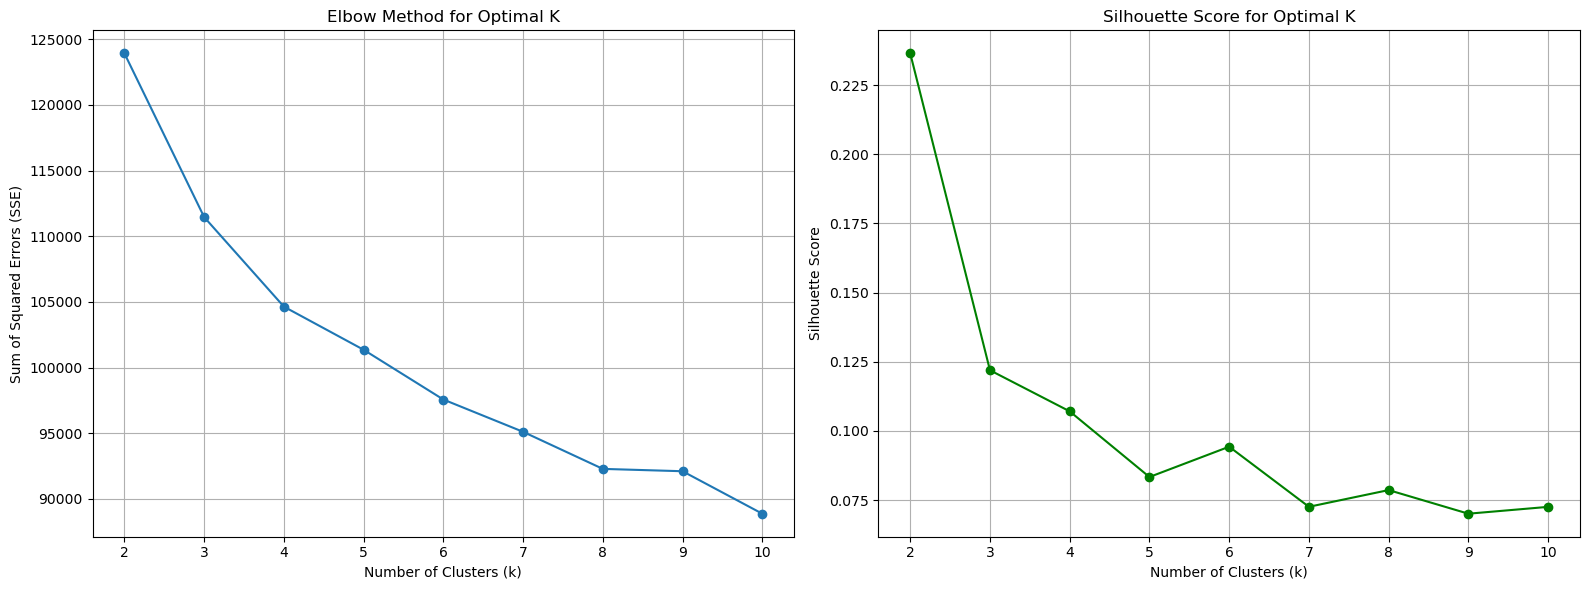

In [537]:
k_meaks_elbow_silhouette_plots(x_train_idh)

In [540]:
# Set the number of clusters
k = 4  # Replace with your known number of clusters

# Perform K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(x_train_idh)

# Get the cluster labels
labels = kmeans.labels_

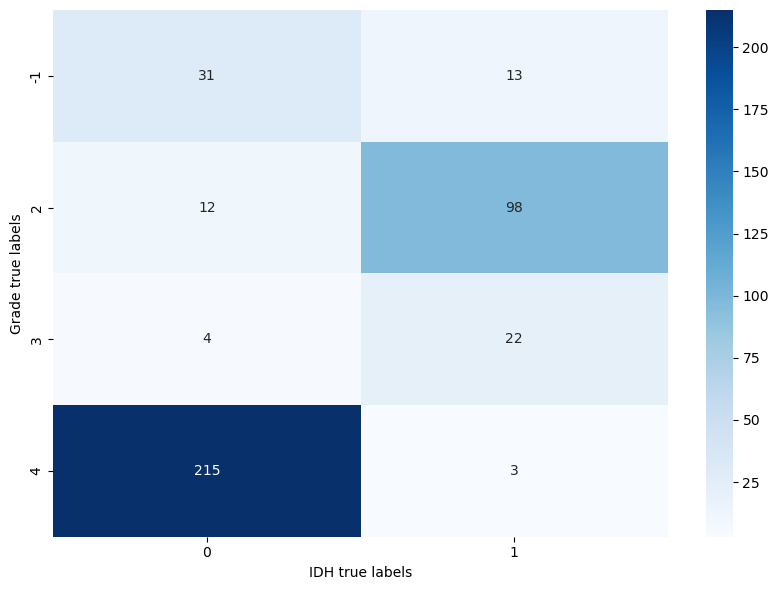

In [466]:
plot_cm([grade_train_idh], y_train_idh, title_true_label_list=['Grade true labels'], cluster_labels_title='IDH true labels')

None


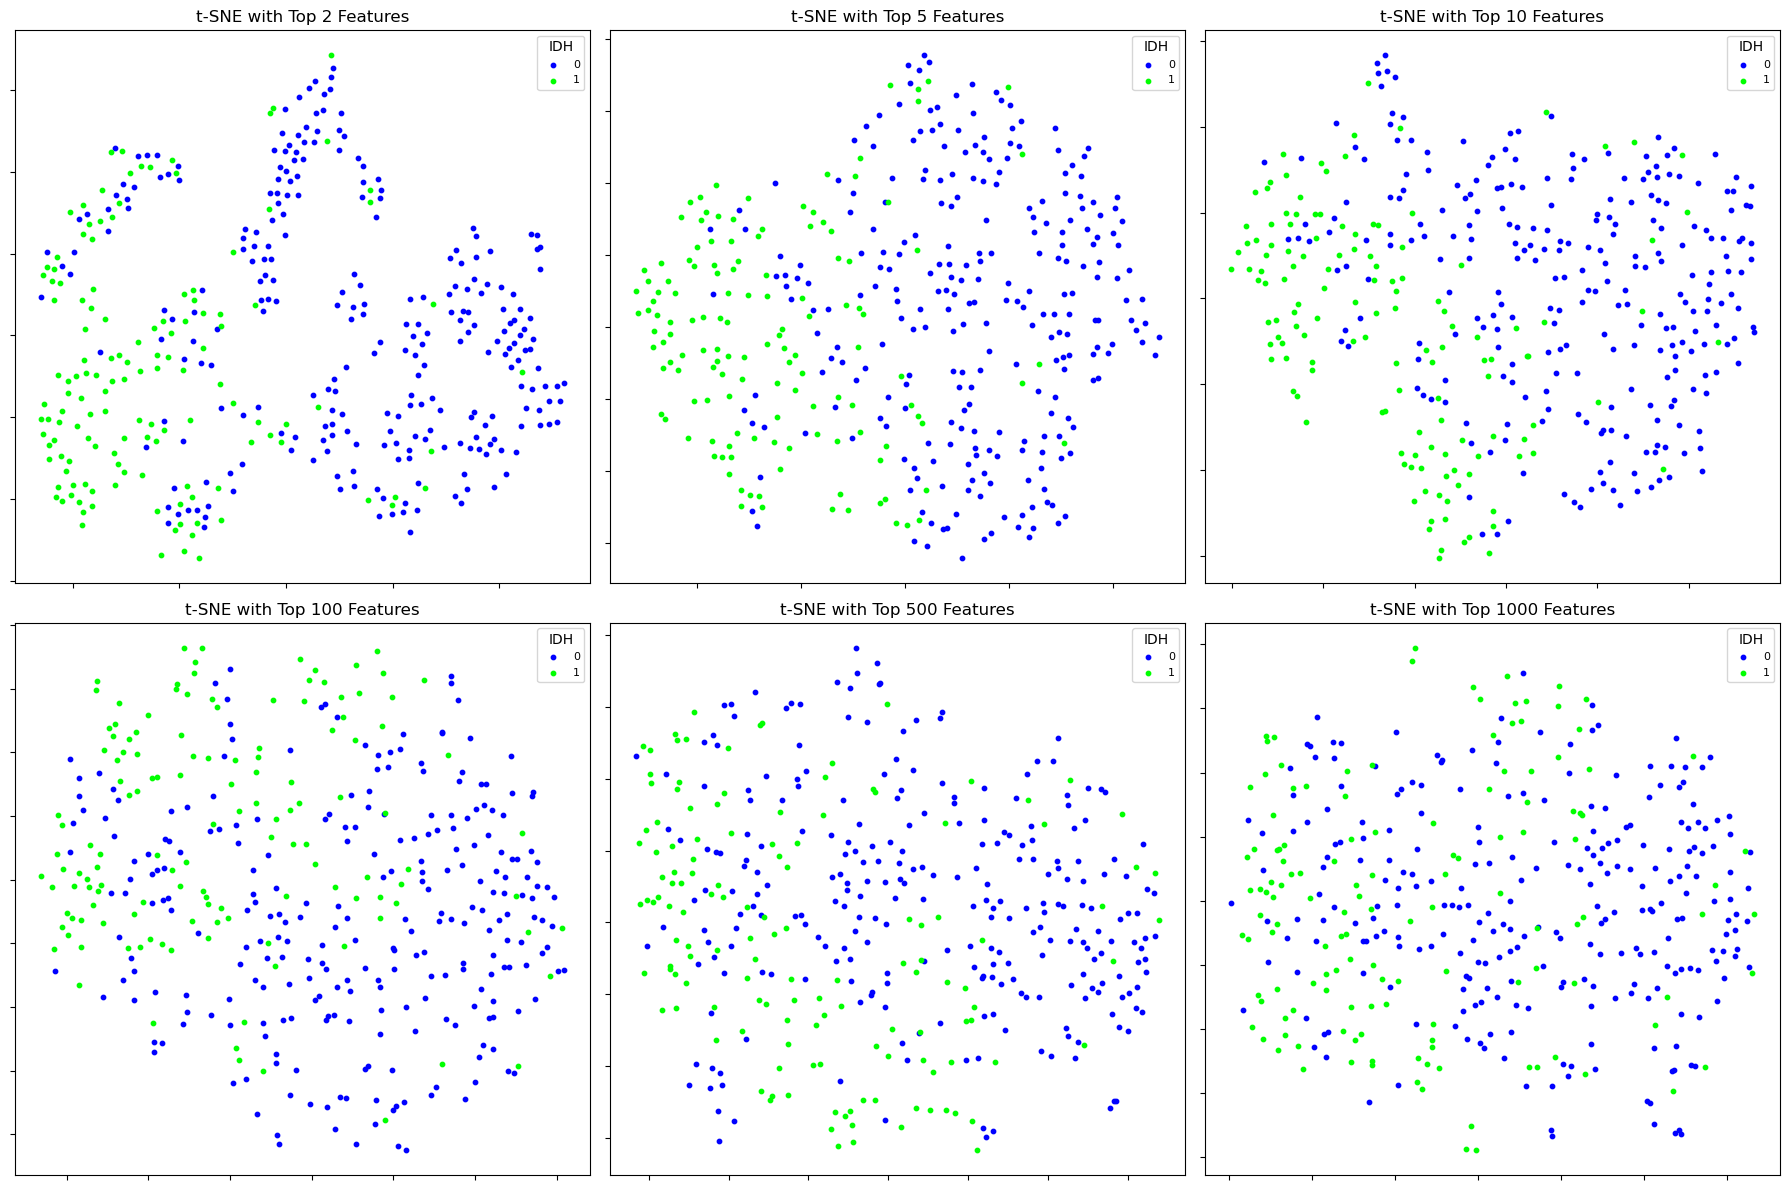

In [467]:
# Define the list of feature counts to test
feature_counts = [2, 5, 10, 100, 500, 1000]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'
t_sne_plots_varying_features(x_train_idh, y_train_idh, feature_counts, labels_title='IDH')

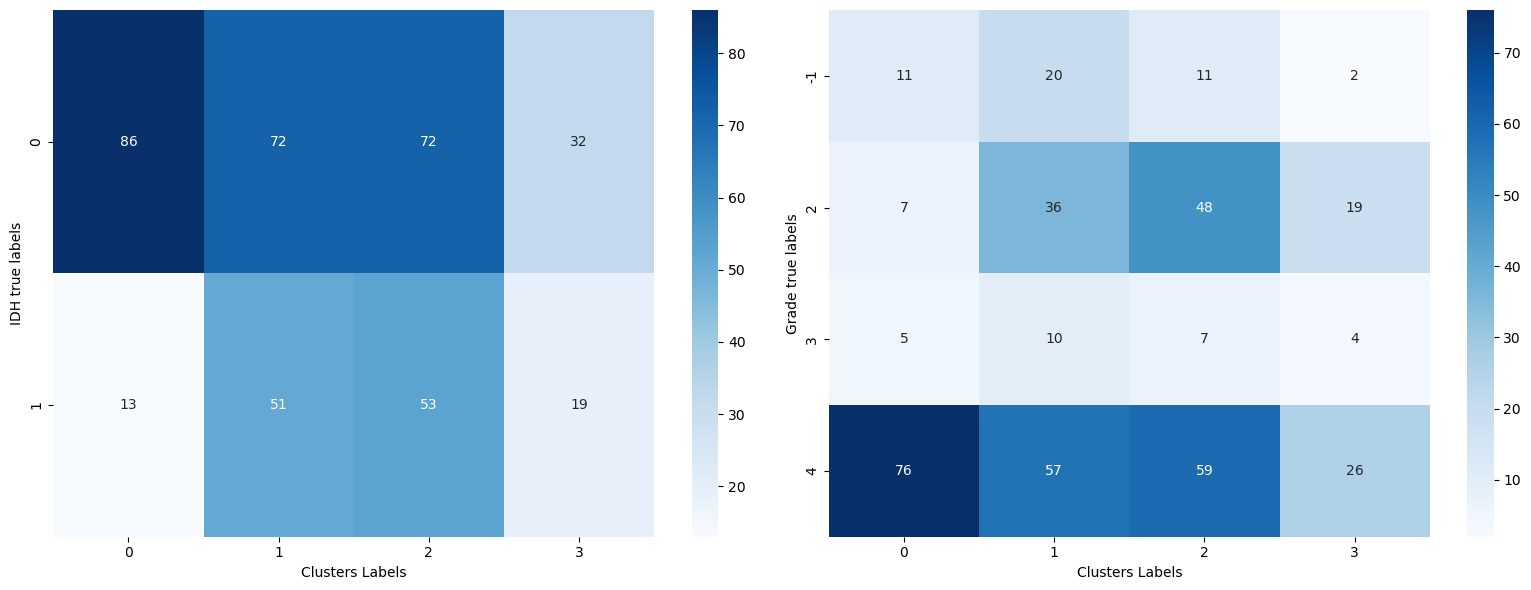

In [541]:
plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH true labels', 'Grade true labels'])

## feature selection by model importancy

In [542]:
num_features=500
data = selection_anaysis(x_train_idh, y_train_idh, 'ANOVA', features=num_features)
#data = data.iloc[:, idh_most_relevant[:20]]

method: ANOVA
Explained Variance (Retained): 4.1327%
Columns from filter 'original': 112
Columns from filter 'exponential': 34
Columns from filter 'gradient': 0
Columns from filter 'lbp-2D': 44
Columns from filter 'lbp-3D-m1': 51
Columns from filter 'lbp-3D-m2': 50
Columns from filter 'lbp-3D-k': 56
Columns from filter 'logarithm': 18
Columns from filter 'square_': 26
Columns from filter 'squareroot': 18
Columns from filter 'wavelet-LLL': 24
Columns from filter 'wavelet-HLL': 2
Columns from filter 'wavelet-LHL': 7
Columns from filter 'wavelet-LLH': 7
Columns from filter 'wavelet-HHL': 12
Columns from filter 'wavelet-HLH': 12
Columns from filter 'wavelet-LHH': 13
Columns from filter 'wavelet-HHH': 13
Wavelet filtered columns: 90
original image columns: 410
Other columns: 1
Columns from image 'original': 129
Columns from image 'mirrored': 124
Columns from contrast 'T1': 125
Columns from contrast 'T2': 262
Columns from contrast 'FLAIR': 112


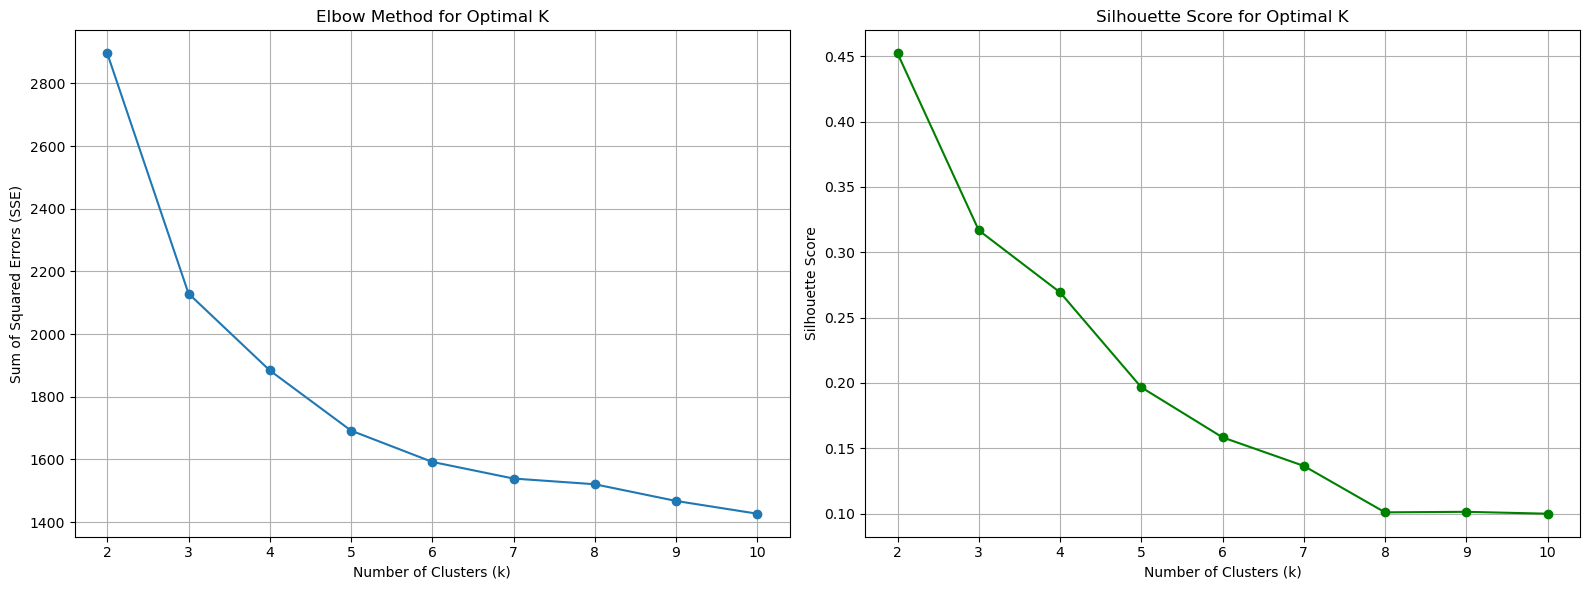

In [543]:
k_meaks_elbow_silhouette_plots(data)

In [544]:
k = 3  # Replace with your known number of clusters

# Perform K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(data)

# Get the cluster labels
labels = kmeans.labels_

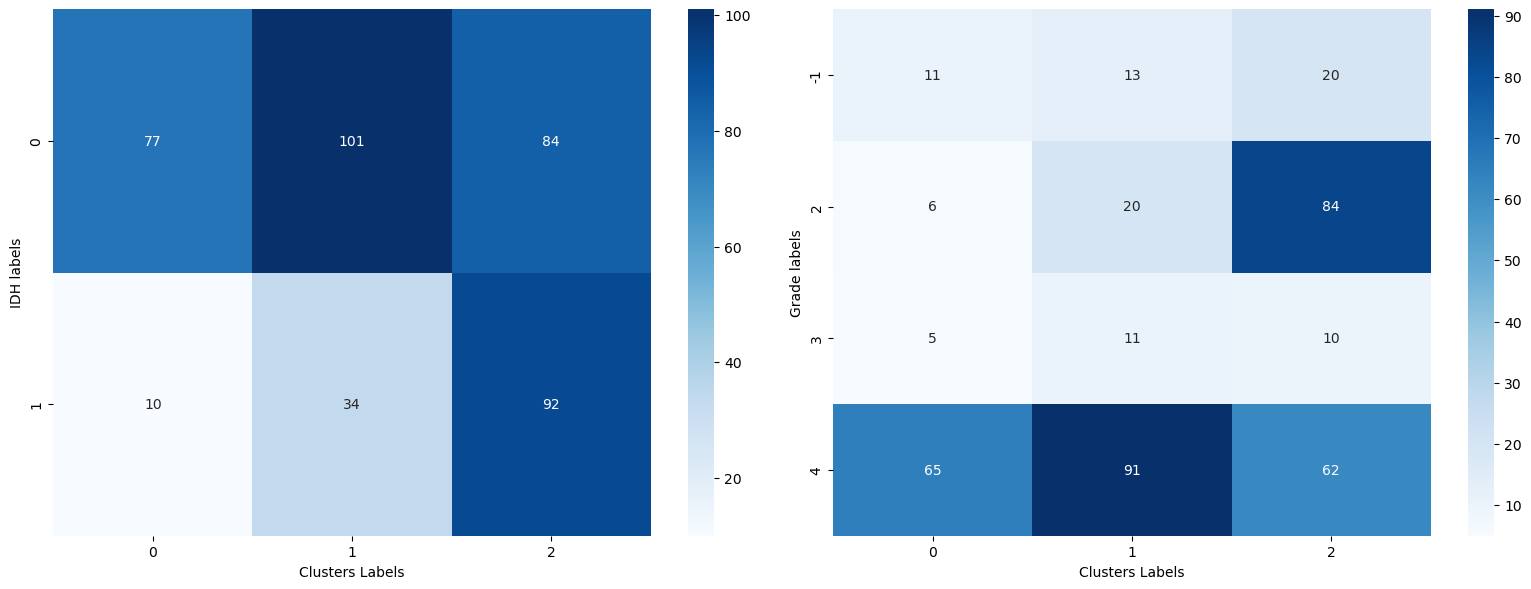

In [545]:
plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH labels', 'Grade labels'])

In [546]:
print(74+92+101, 10+87+34)

267 131


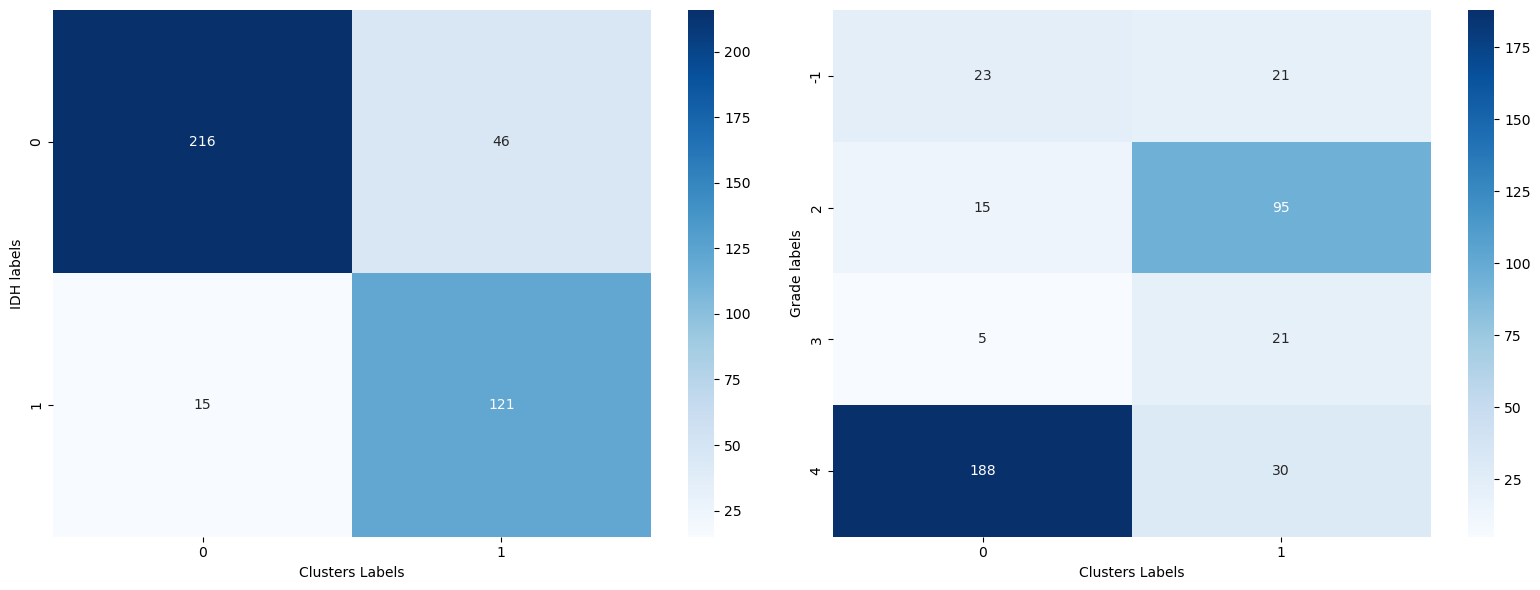

In [547]:
k = 2  # Replace with your known number of clusters

# Perform K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(data.iloc[:, idh_train_most_relevant[:10]])

# Get the cluster labels
labels = kmeans.labels_

plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH labels', 'Grade labels'])

In [548]:
(len(y_train_idh)-(46+15)) /len(y_train_idh)

0.8467336683417085

In [448]:
(len(y_train_idh)-(10+17+32)) /len(y_train_idh)

0.8517587939698492

None


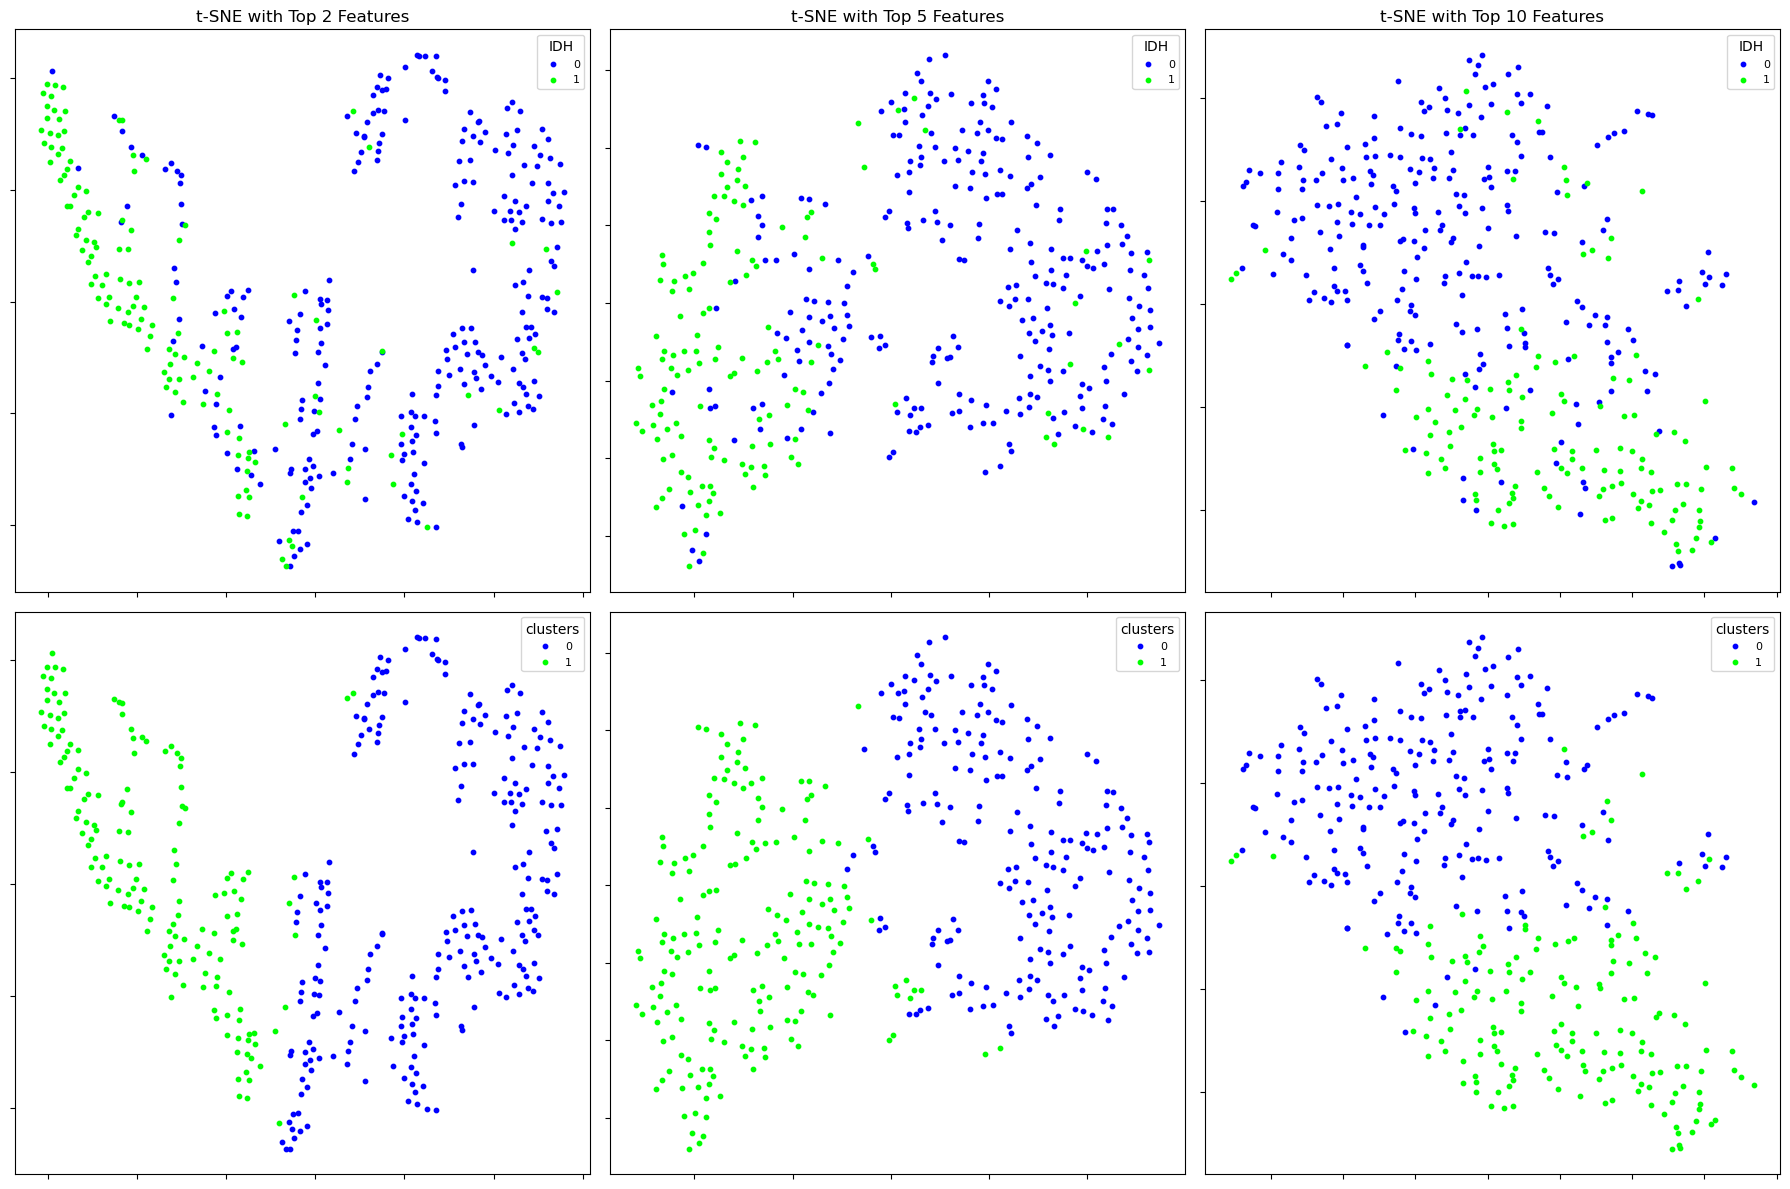

In [549]:
# Define the list of feature counts to test
feature_counts = [2, 5, 10]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, y_train_idh, 2, feature_counts, idh_train_most_relevant, 'KMEANS', labels_title='IDH', labels_title_clusters='clusters')

None


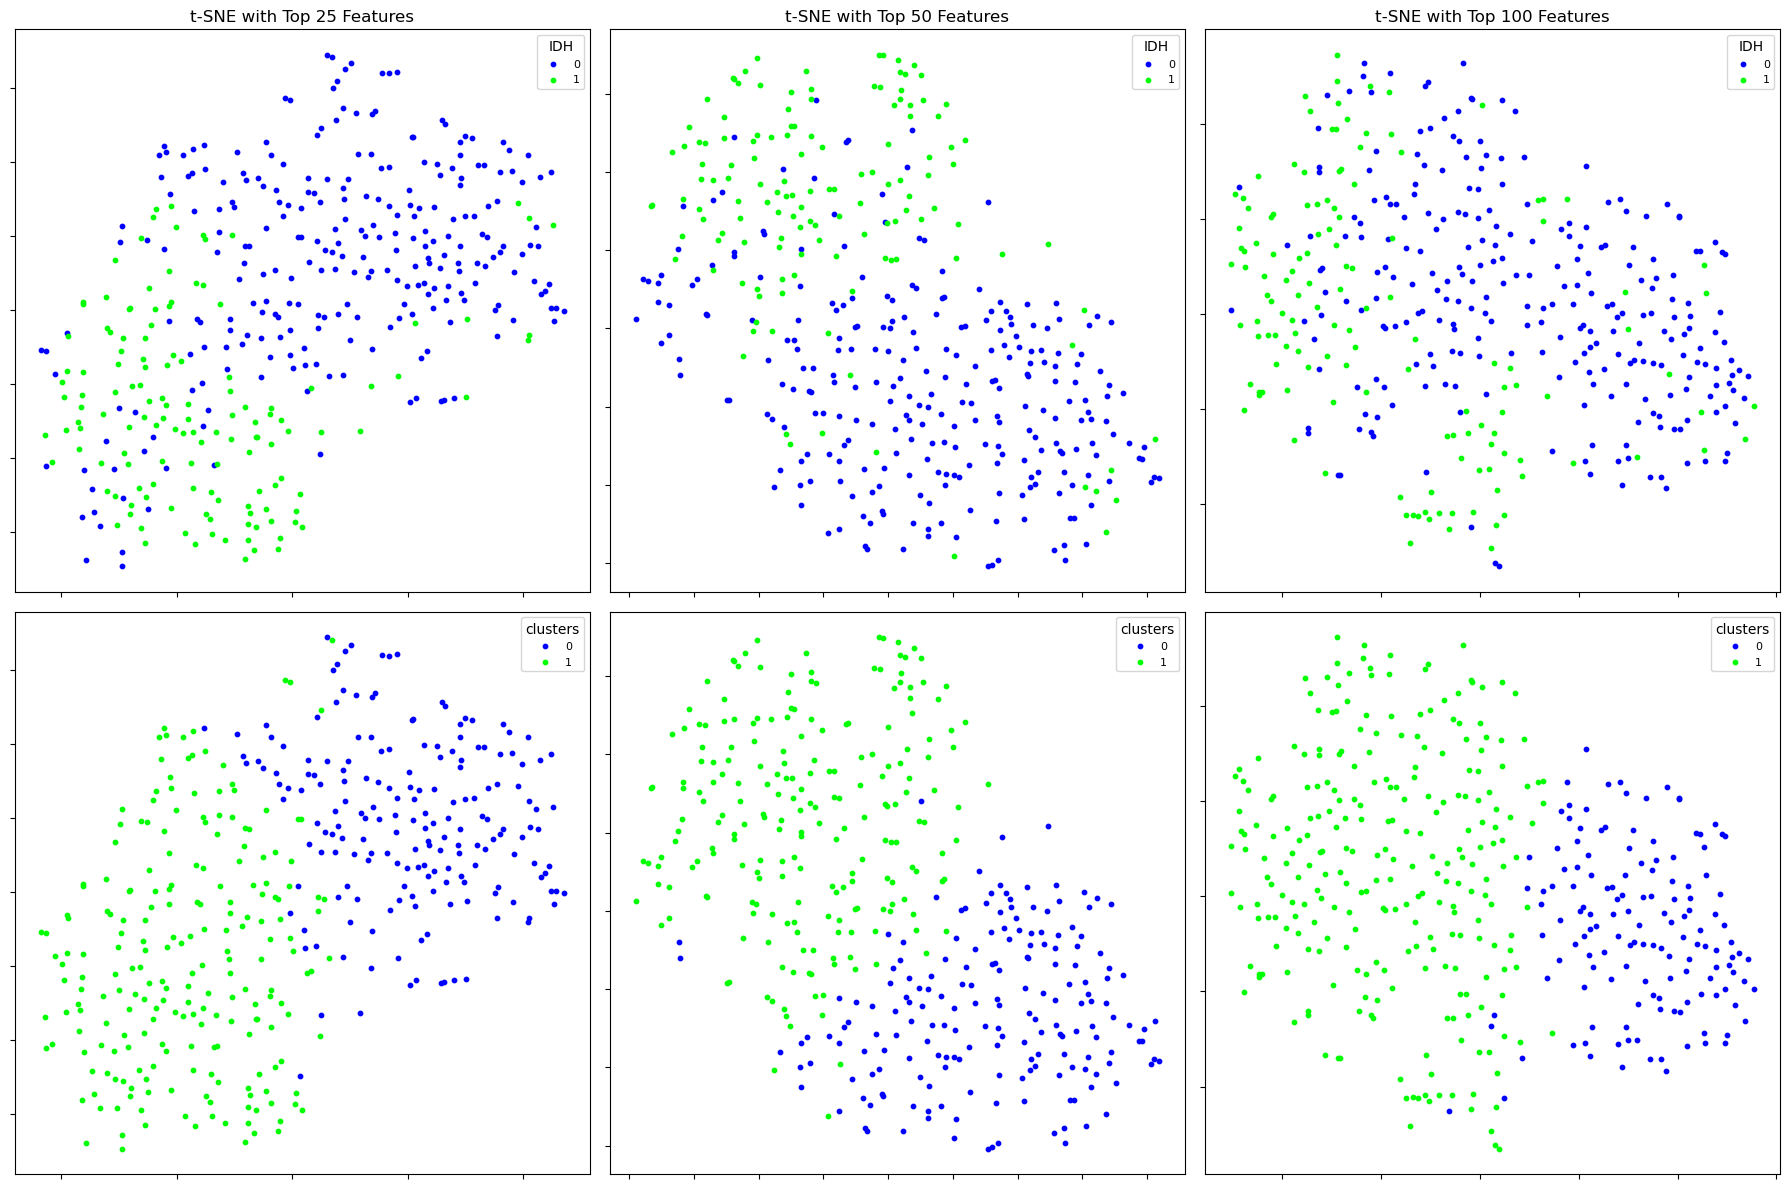

In [550]:
# Define the list of feature counts to test
feature_counts = [25, 50, 100]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, y_train_idh, 2, feature_counts, idh_train_most_relevant, 'KMEANS', labels_title='IDH', labels_title_clusters='clusters')

None


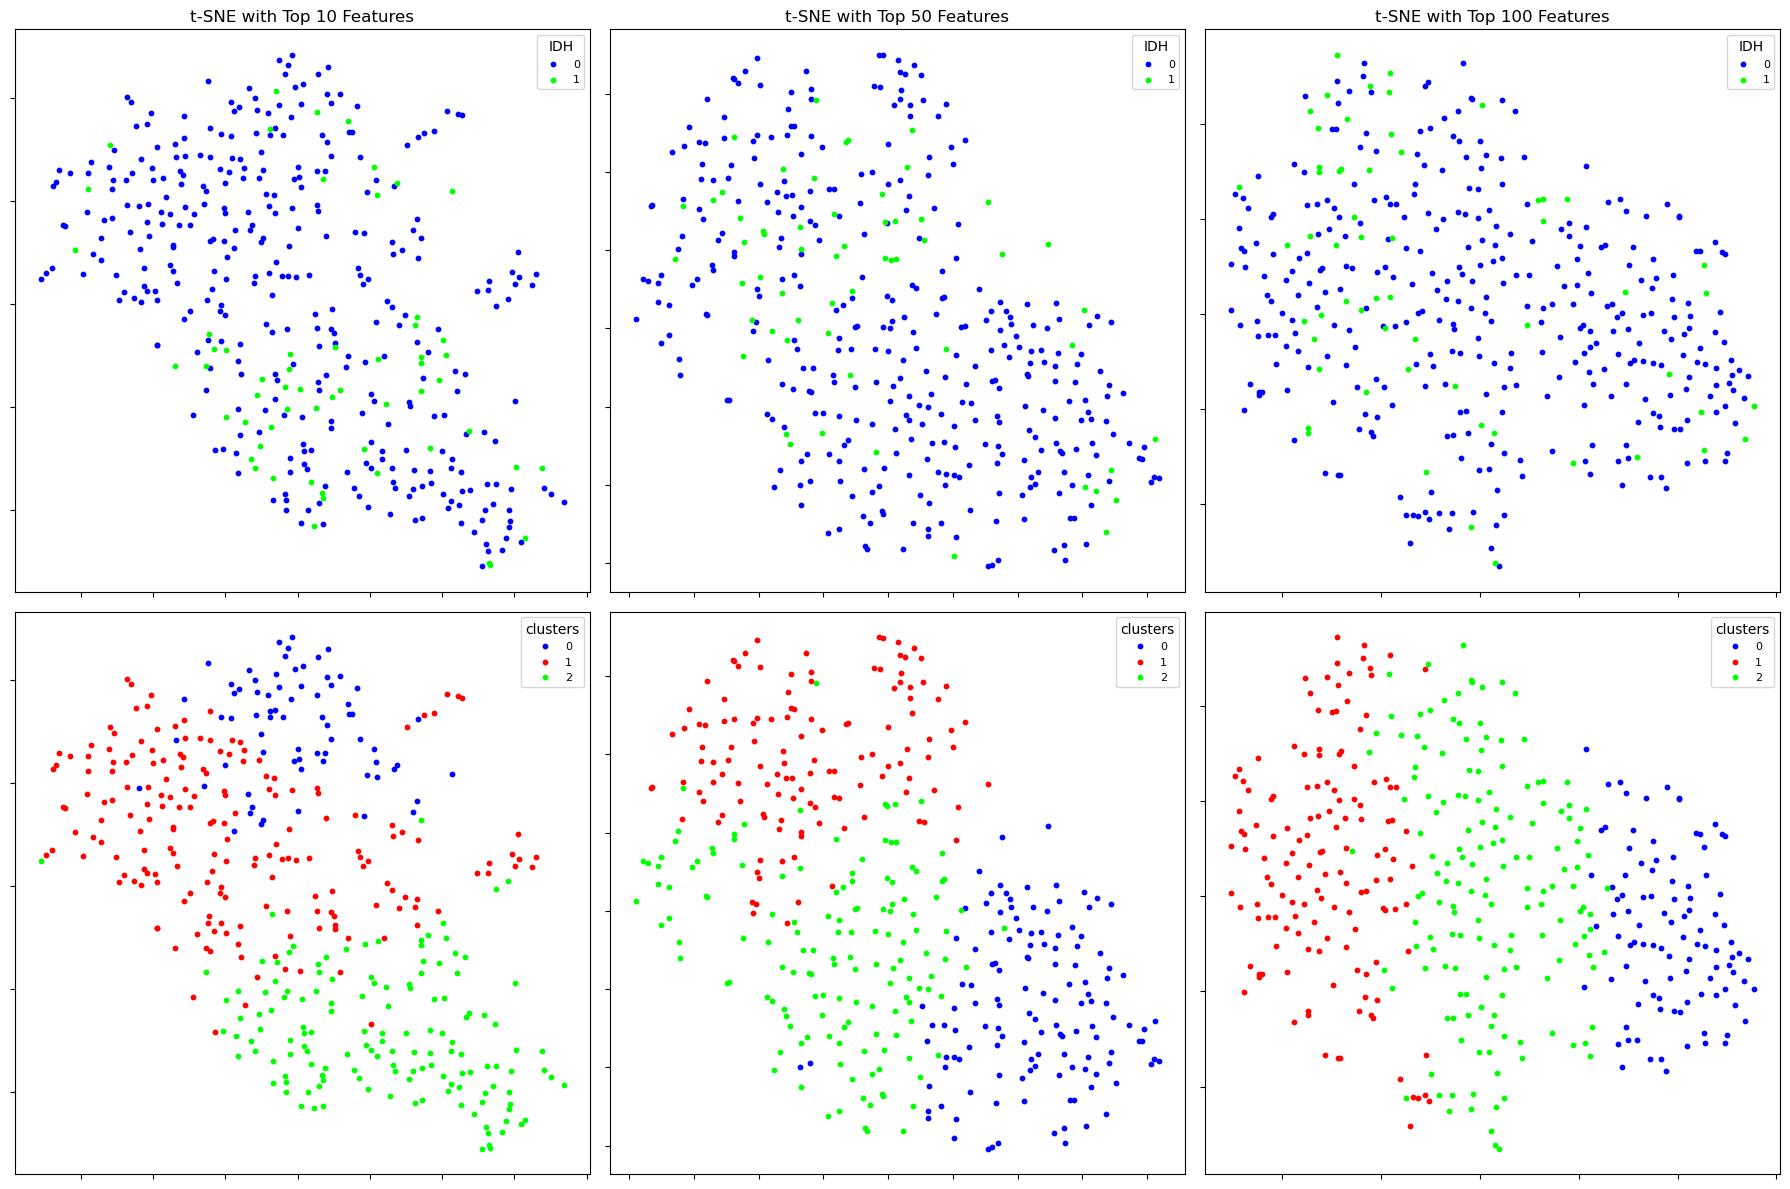

In [438]:
# Define the list of feature counts to test
feature_counts = [10, 50, 100]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, miss_classified, 3, feature_counts, idh_train_most_relevant, 'KMEANS', labels_title='IDH', labels_title_clusters='clusters')

None


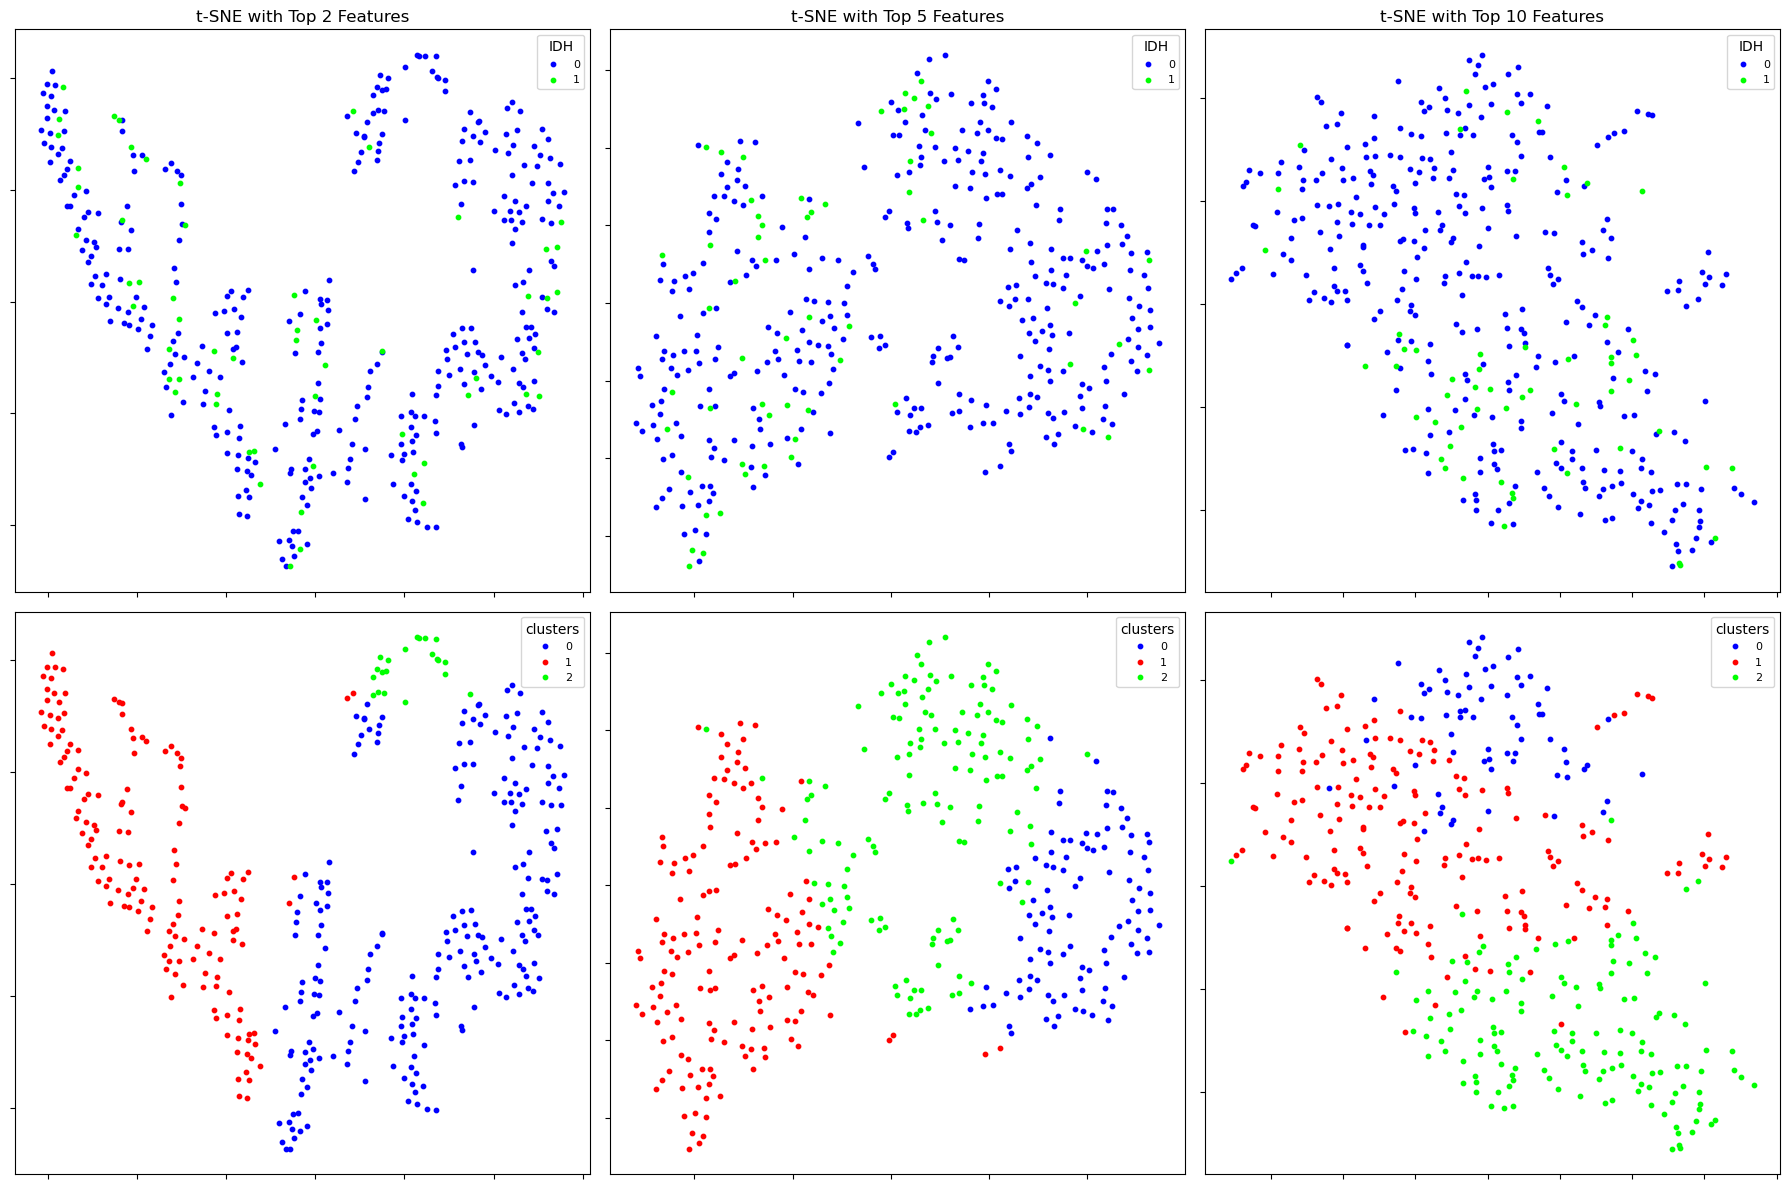

In [439]:
# Define the list of feature counts to test
feature_counts = [2, 5, 10]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, miss_classified, 3, feature_counts, idh_train_most_relevant, 'KMEANS', labels_title='IDH', labels_title_clusters='clusters')

In [436]:
miss_classified = np.where(((labels == 1) & (y_train_idh == 0)) | ((np.isin(labels, [0, 2])) & (y_train_idh == 1)), 1, 0)
sum(miss_classified)

58

## 1p19q

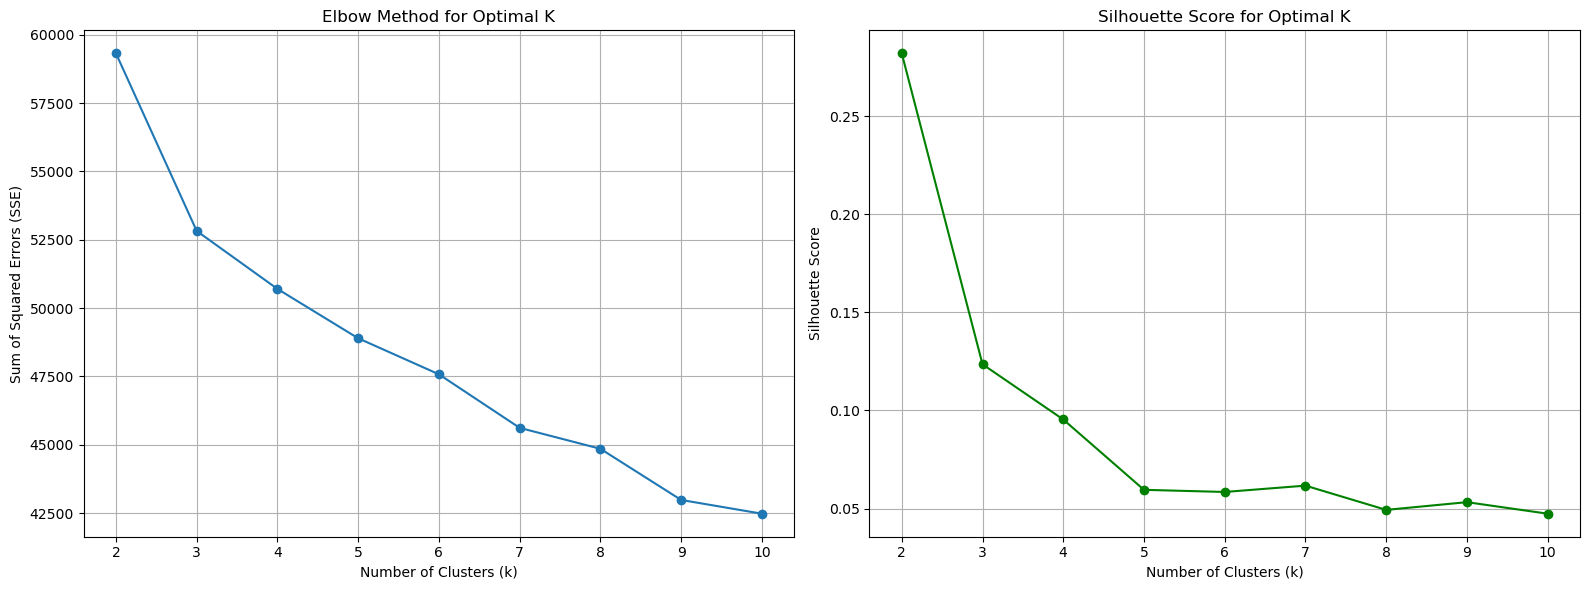

In [40]:
k_meaks_elbow_silhouette_plots(x_train_merged)

In [49]:
# Set the number of clusters
k = 5  # Replace with your known number of clusters

# Perform K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(x_train_merged)

# Get the cluster labels
labels = kmeans.labels_

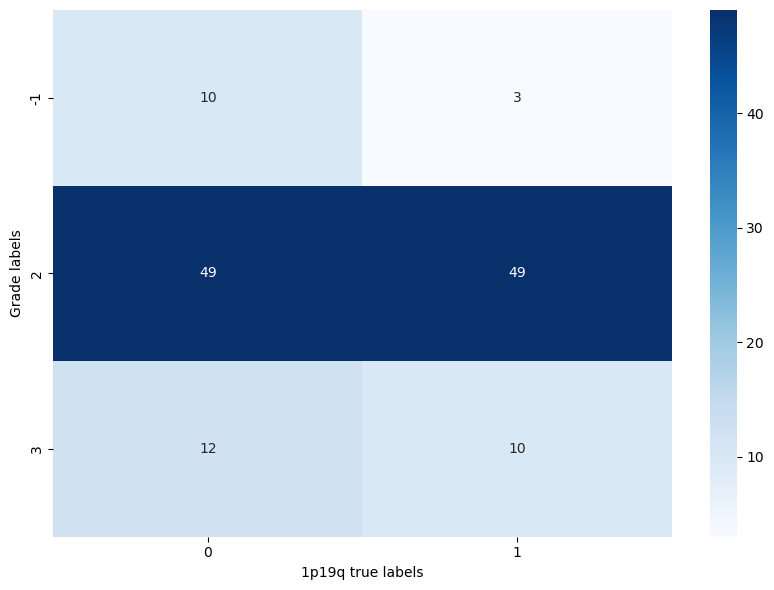

In [50]:
plot_cm([grade_train_merged], y_train_merged, title_true_label_list=['Grade labels'], cluster_labels_title='1p19q true labels')

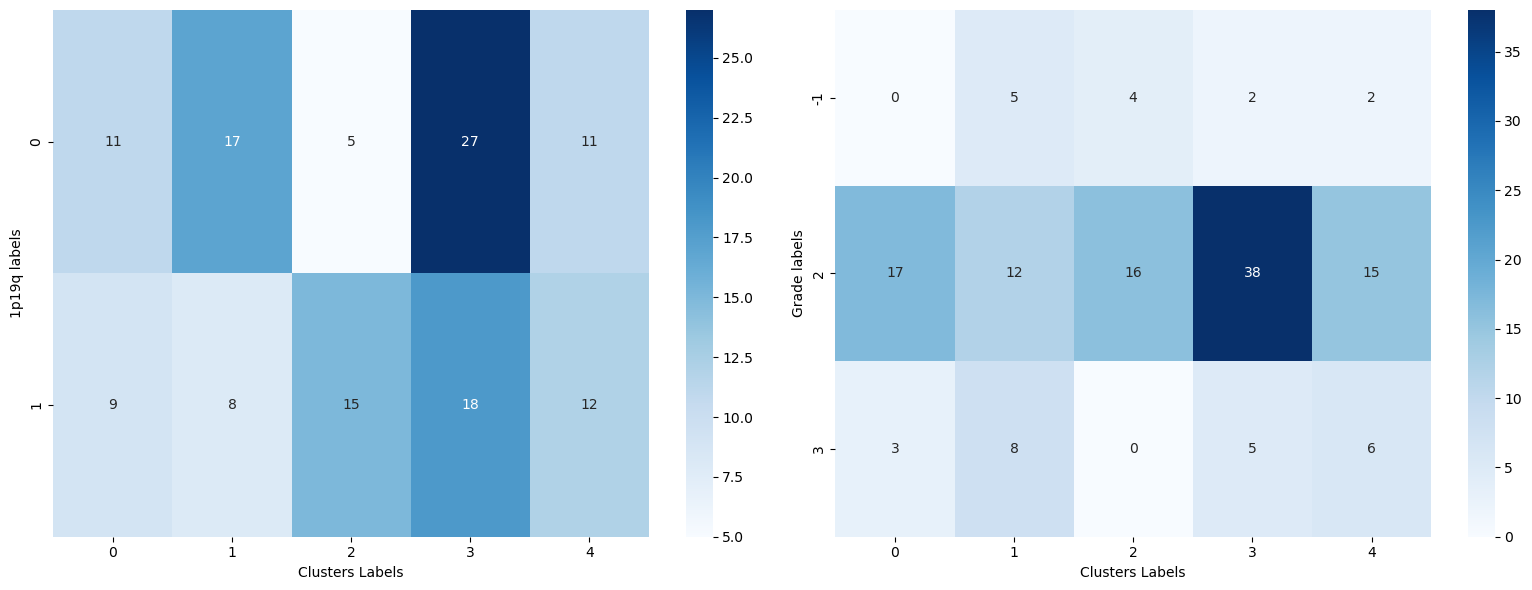

In [51]:
plot_cm([y_train_merged, grade_train_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

In [87]:
num_features=100
data = selection_anaysis(x_train_merged, y_train_merged, 'ANOVA', features=num_features)

method: ANOVA
Explained Variance (Retained): 0.5540%
Columns from filter 'original': 11
Columns from filter 'exponential': 16
Columns from filter 'gradient': 14
Columns from filter 'lbp-2D': 0
Columns from filter 'lbp-3D-m1': 2
Columns from filter 'lbp-3D-m2': 1
Columns from filter 'lbp-3D-k': 4
Columns from filter 'logarithm': 4
Columns from filter 'square_': 24
Columns from filter 'squareroot': 5
Columns from filter 'wavelet-LLL': 11
Columns from filter 'wavelet-HLL': 3
Columns from filter 'wavelet-LHL': 3
Columns from filter 'wavelet-LLH': 0
Columns from filter 'wavelet-HHL': 0
Columns from filter 'wavelet-HLH': 0
Columns from filter 'wavelet-LHH': 1
Columns from filter 'wavelet-HHH': 0
Wavelet filtered columns: 18
original image columns: 82
Other columns: 1
Columns from image 'original': 29
Columns from image 'mirrored': 0
Columns from contrast 'T1': 21
Columns from contrast 'T2': 78
Columns from contrast 'FLAIR': 0


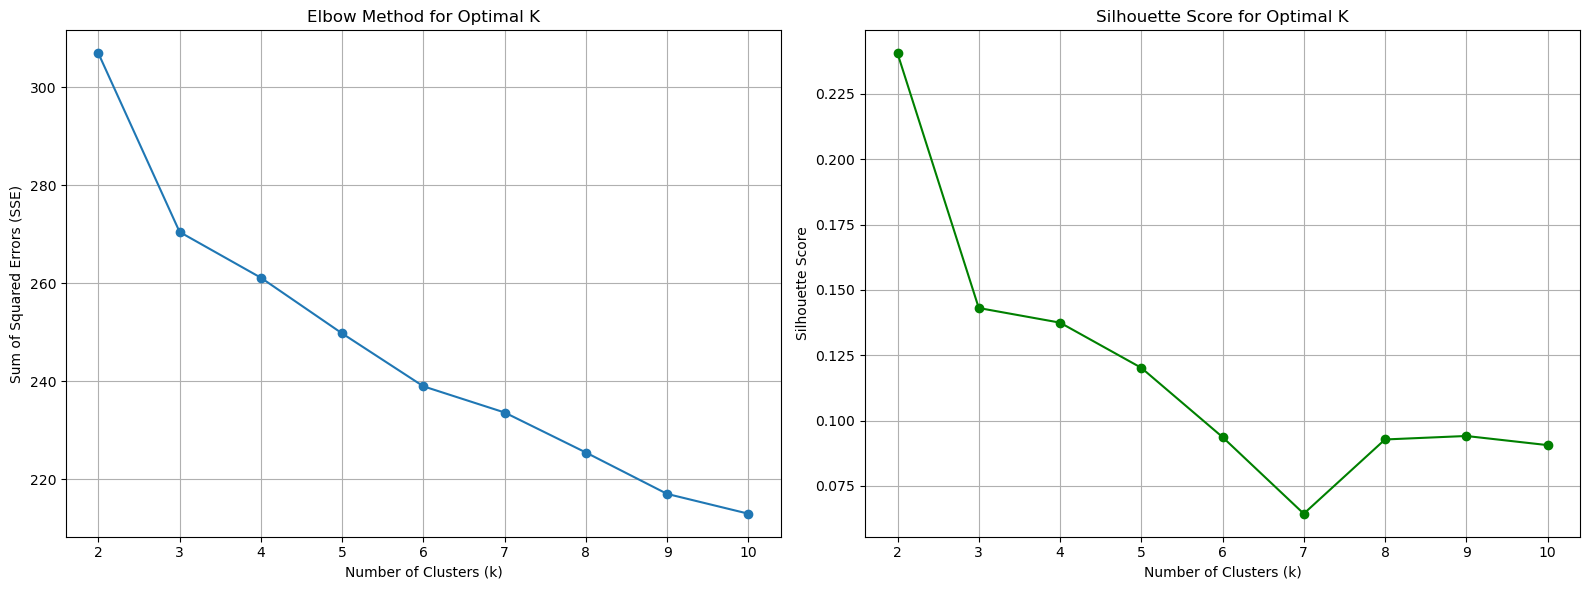

In [88]:
k_meaks_elbow_silhouette_plots(data)

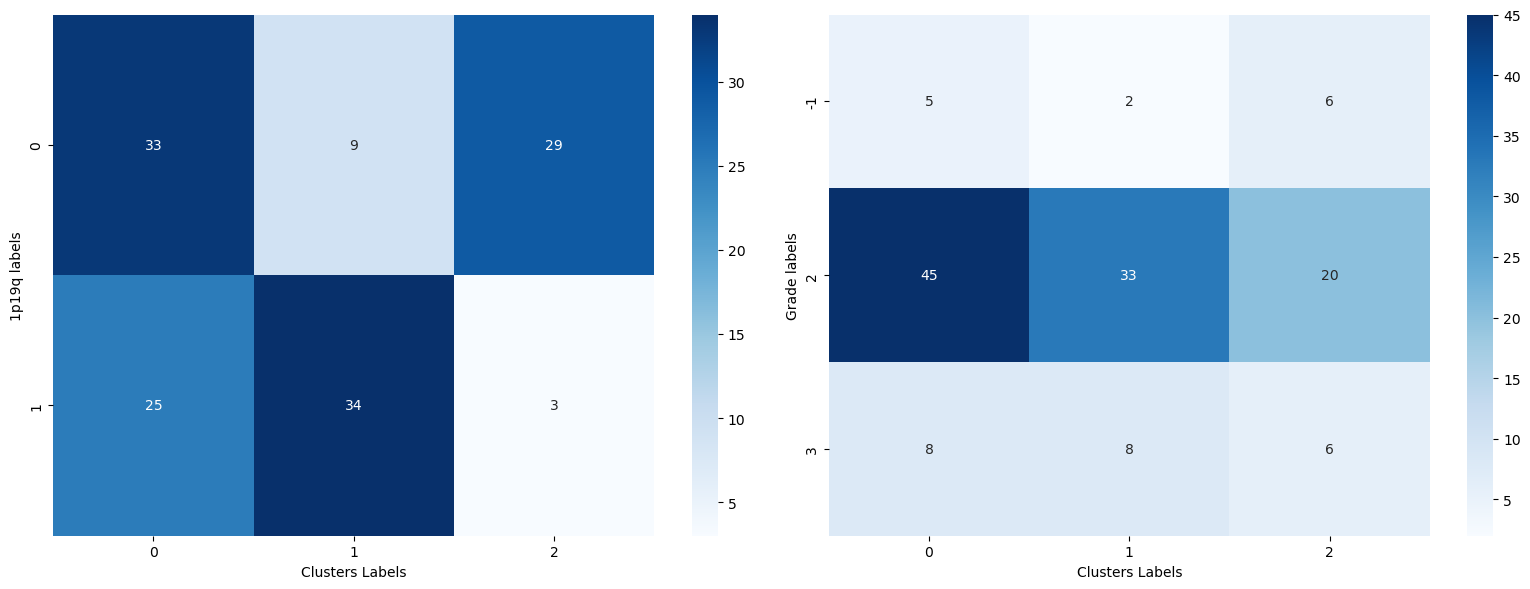

In [90]:
k = 3 # Replace with your known number of clusters

# Perform K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(data)

# Get the cluster labels
labels = kmeans.labels_

plot_cm([y_train_merged, grade_train_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

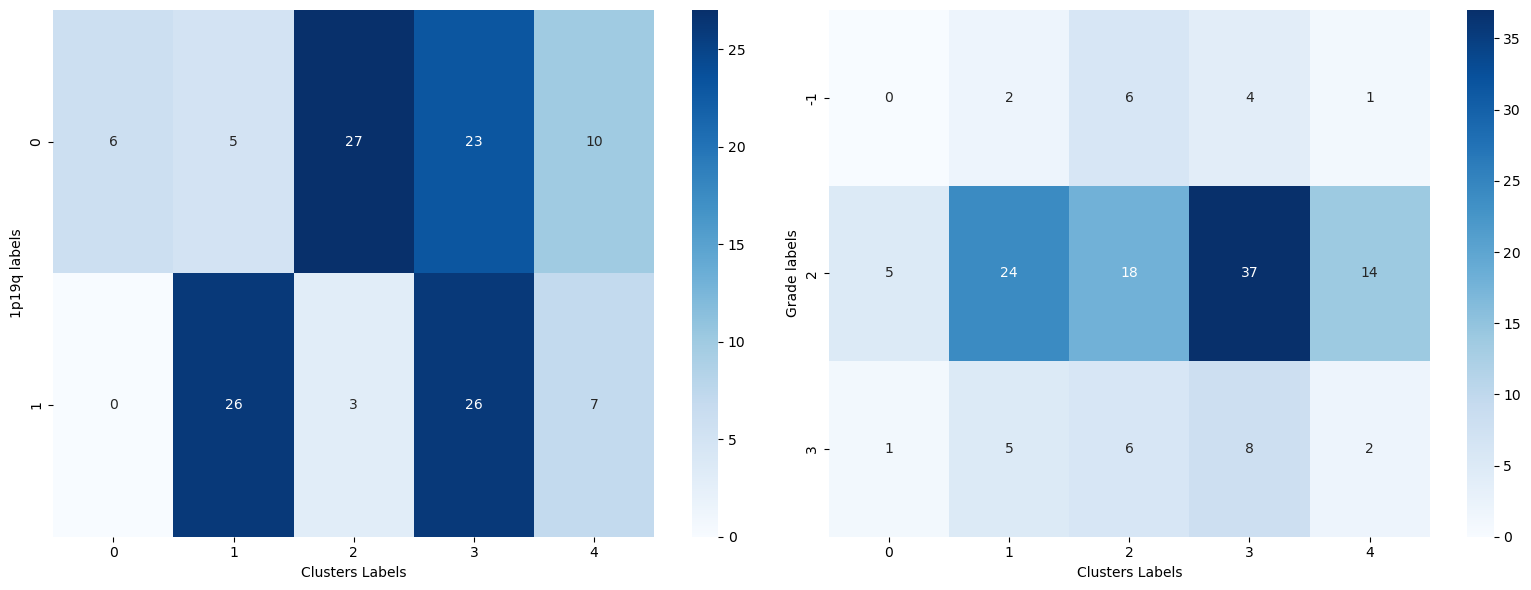

In [91]:
k = 5 # Replace with your known number of clusters

# Perform K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(data)

# Get the cluster labels
labels = kmeans.labels_

plot_cm([y_train_merged, grade_train_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

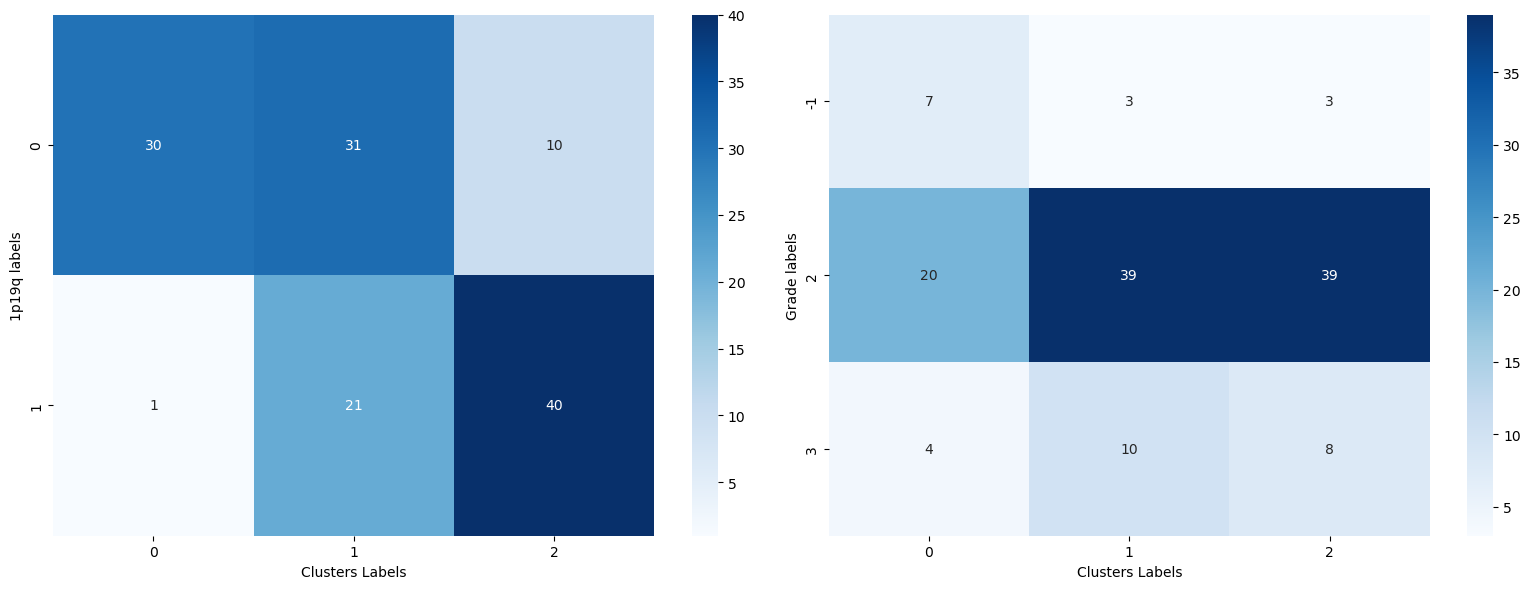

In [92]:
k = 3  # Replace with your known number of clusters

# Perform K-Means clustering
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(data.iloc[:, merged_train_most_relevant[:10]])

# Get the cluster labels
labels = kmeans.labels_

plot_cm([y_train_merged, grade_train_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

None


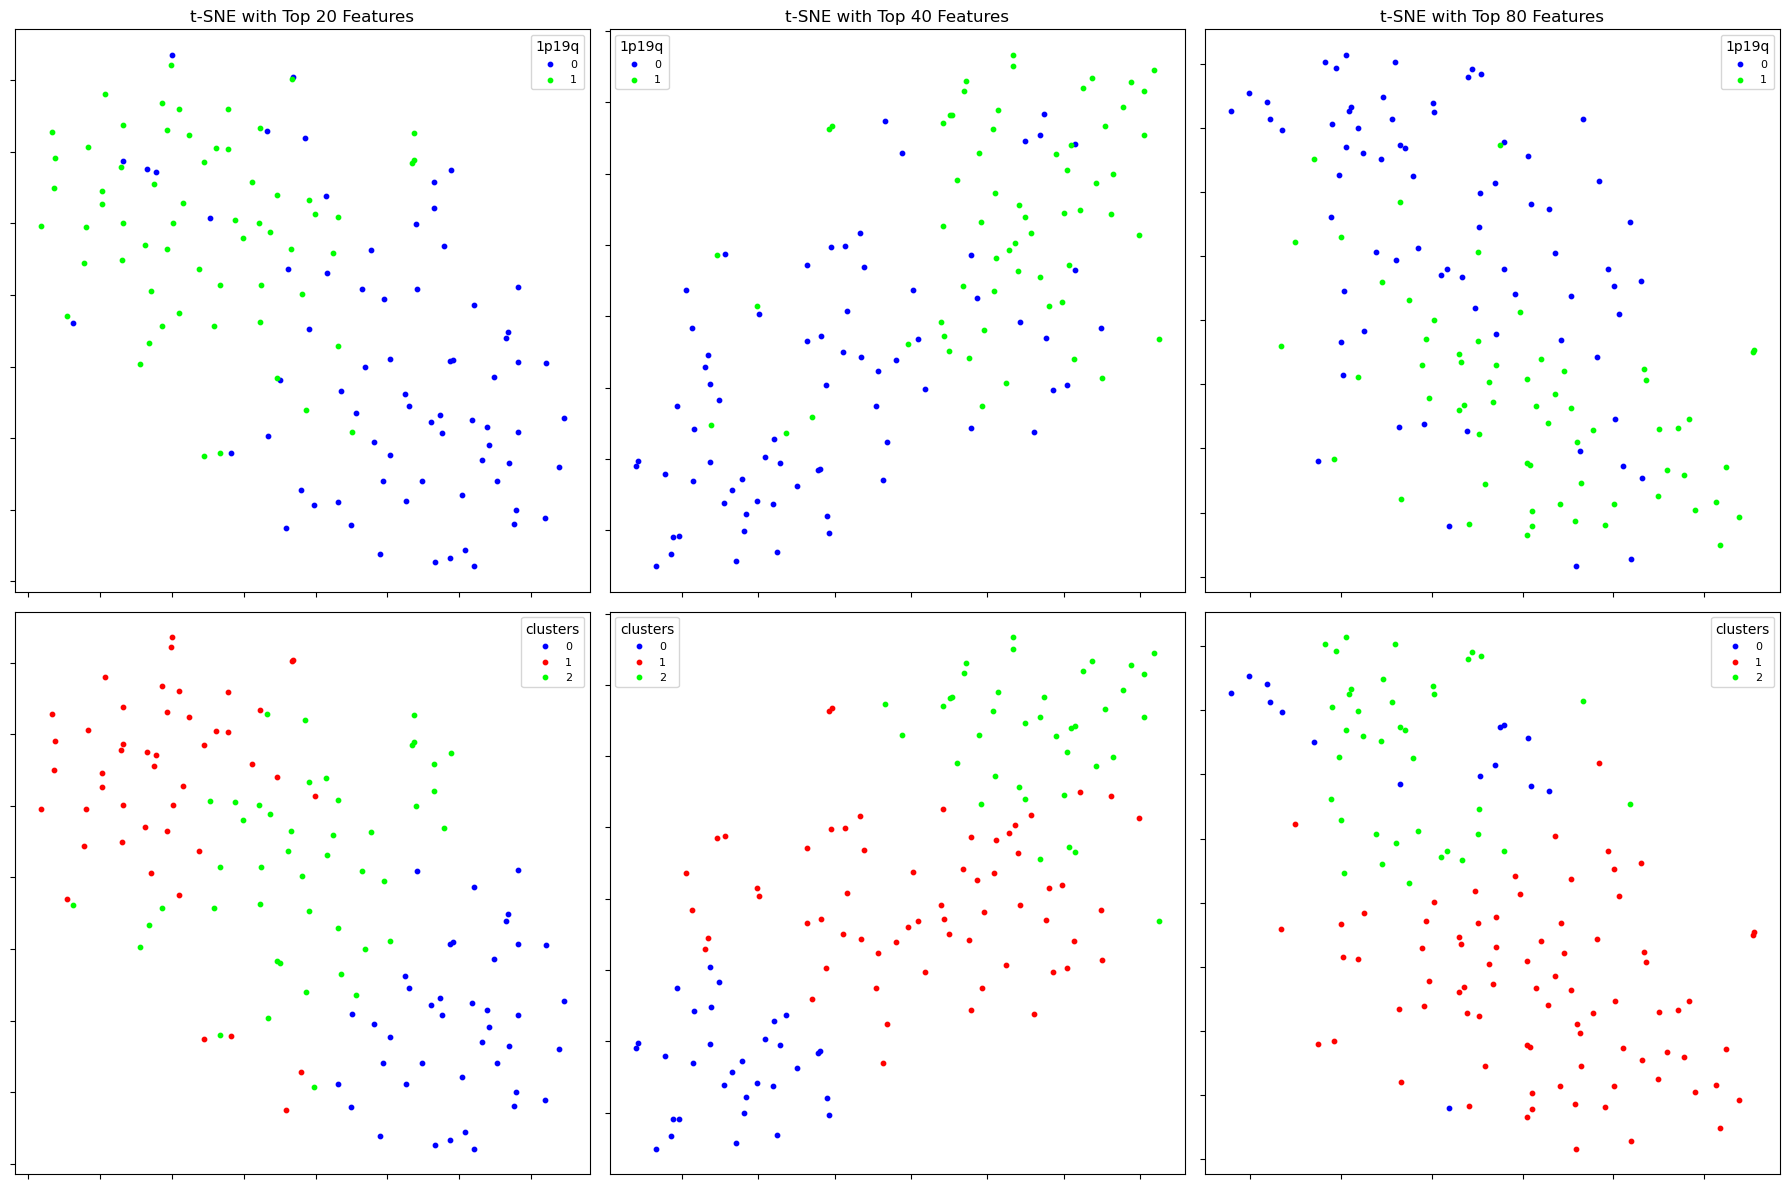

In [74]:
# Define the list of feature counts to test
feature_counts = [20, 40, 80]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, y_train_merged, 3, feature_counts, merged_train_most_relevant, clustering_method='KMEANS', labels_title='1p19q', labels_title_clusters='clusters')

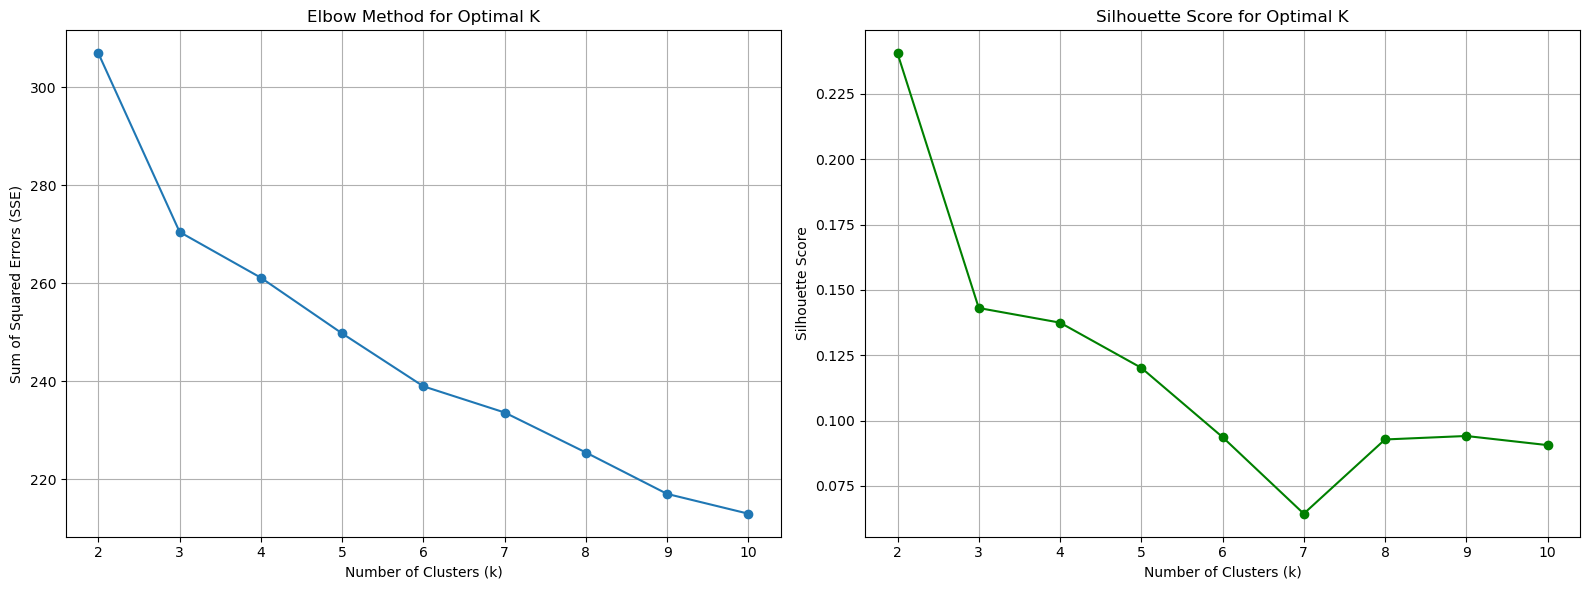

In [347]:
k_meaks_elbow_silhouette_plots(data)

## DBSCAN

In [113]:
num_features=500
data = selection_anaysis(x_train_idh, y_train_idh, 'ANOVA', features=num_features)

method: ANOVA
Explained Variance (Retained): 4.1327%
Columns from filter 'original': 112
Columns from filter 'exponential': 34
Columns from filter 'gradient': 0
Columns from filter 'lbp-2D': 44
Columns from filter 'lbp-3D-m1': 51
Columns from filter 'lbp-3D-m2': 50
Columns from filter 'lbp-3D-k': 56
Columns from filter 'logarithm': 18
Columns from filter 'square_': 26
Columns from filter 'squareroot': 18
Columns from filter 'wavelet-LLL': 24
Columns from filter 'wavelet-HLL': 2
Columns from filter 'wavelet-LHL': 7
Columns from filter 'wavelet-LLH': 7
Columns from filter 'wavelet-HHL': 12
Columns from filter 'wavelet-HLH': 12
Columns from filter 'wavelet-LHH': 13
Columns from filter 'wavelet-HHH': 13
Wavelet filtered columns: 90
original image columns: 410
Other columns: 1
Columns from image 'original': 129
Columns from image 'mirrored': 124
Columns from contrast 'T1': 125
Columns from contrast 'T2': 262
Columns from contrast 'FLAIR': 112


In [112]:
# Set DBSCAN parameters
epsilon = 0.8 # Maximum distance between two samples for them to be considered neighbors
min_samples = 5  # Minimum number of samples required to form a dense region

# Perform DBSCAN clustering
dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)
dbscan.fit(data)

# Get cluster labels (-1 represents noise/outliers)
labels = dbscan.labels_

# Add labels to the dataset if using a Pandas DataFrame
# data['Cluster'] = labels  # Uncomment if using a DataFrame

# Print results
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print(f"Number of clusters: {n_clusters}")
print(f"Number of noise points: {n_noise}")

# If there are more than one cluster, calculate silhouette score
if n_clusters > 1:
    silhouette = silhouette_score(data, labels)
    print(f"Silhouette Score: {silhouette:.2f}")
else:
    print("Silhouette Score not available (only one cluster found).")

Number of clusters: 2
Number of noise points: 250
Silhouette Score: -0.11


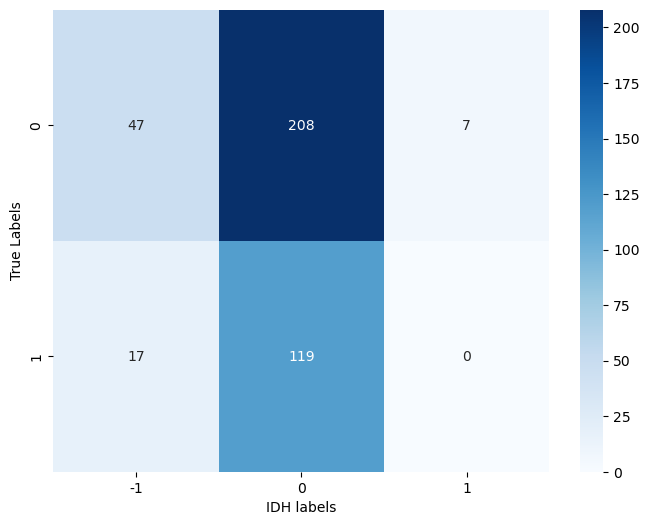

In [104]:
plot_cm(y_train_idh, labels, cluster_labels_title='IDH labels')

In [119]:
import hdbscan

clusterer = hdbscan.HDBSCAN(min_samples=50)
labels = clusterer.fit_predict(data)

# Add labels to the dataset if using a Pandas DataFrame
# data['Cluster'] = labels  # Uncomment if using a DataFrame

# Print results
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print(f"Number of clusters: {n_clusters}")
print(f"Number of noise points: {n_noise}")

# If there are more than one cluster, calculate silhouette score
if n_clusters > 1:
    silhouette = silhouette_score(data, labels)
    print(f"Silhouette Score: {silhouette:.2f}")
else:
    print("Silhouette Score not available (only one cluster found).")

Number of clusters: 0
Number of noise points: 398
Silhouette Score not available (only one cluster found).


## Gaussian mixture

### IDH

In [7]:
num_features=500
data = selection_anaysis(x_train_idh, y_train_idh, 'ANOVA', features=num_features)

method: ANOVA
Explained Variance (Retained): 4.1327%
Columns from filter 'original': 112
Columns from filter 'exponential': 34
Columns from filter 'gradient': 0
Columns from filter 'lbp-2D': 44
Columns from filter 'lbp-3D-m1': 51
Columns from filter 'lbp-3D-m2': 50
Columns from filter 'lbp-3D-k': 56
Columns from filter 'logarithm': 18
Columns from filter 'square_': 26
Columns from filter 'squareroot': 18
Columns from filter 'wavelet-LLL': 24
Columns from filter 'wavelet-HLL': 2
Columns from filter 'wavelet-LHL': 7
Columns from filter 'wavelet-LLH': 7
Columns from filter 'wavelet-HHL': 12
Columns from filter 'wavelet-HLH': 12
Columns from filter 'wavelet-LHH': 13
Columns from filter 'wavelet-HHH': 13
Wavelet filtered columns: 90
original image columns: 410
Other columns: 1
Columns from image 'original': 129
Columns from image 'mirrored': 124
Columns from contrast 'T1': 125
Columns from contrast 'T2': 262
Columns from contrast 'FLAIR': 112


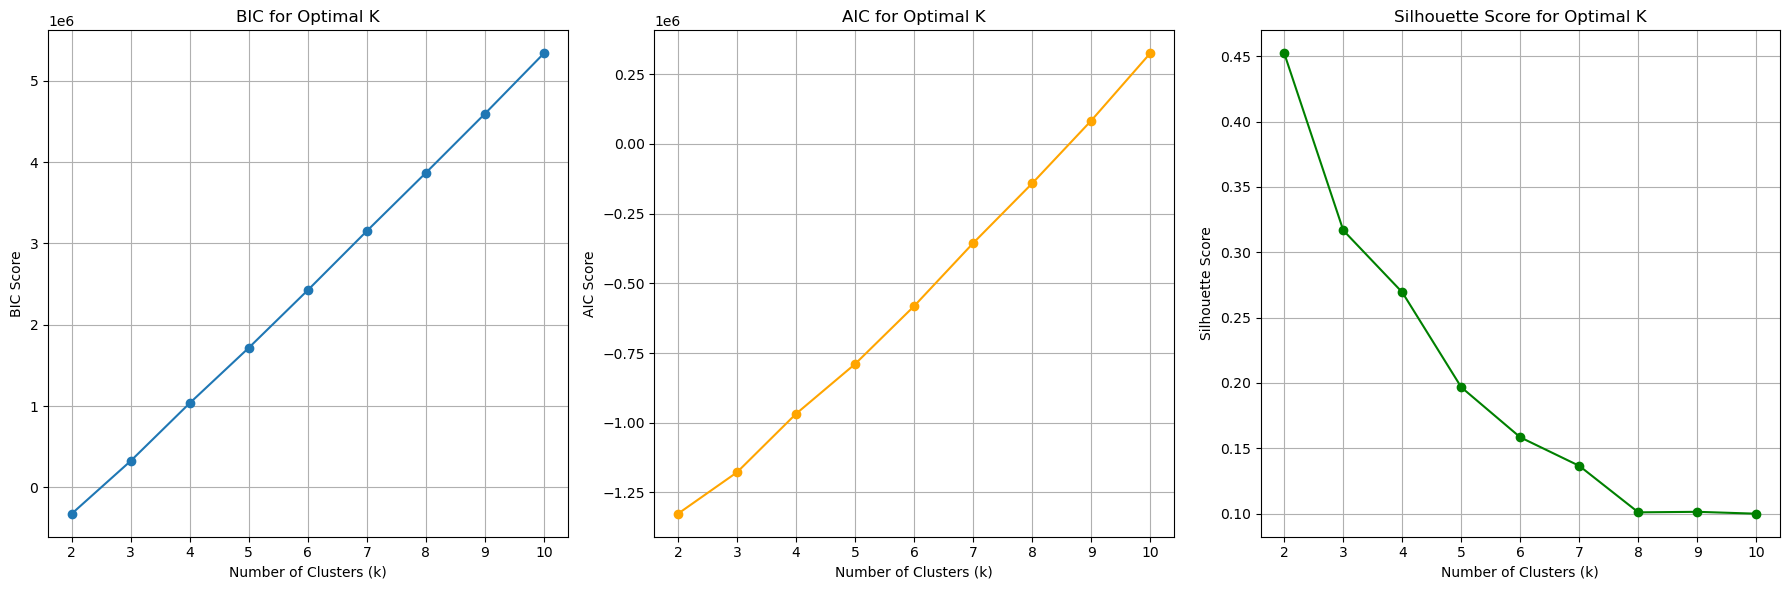

In [8]:
gmm_bic_aic_silhouette_plots(data)

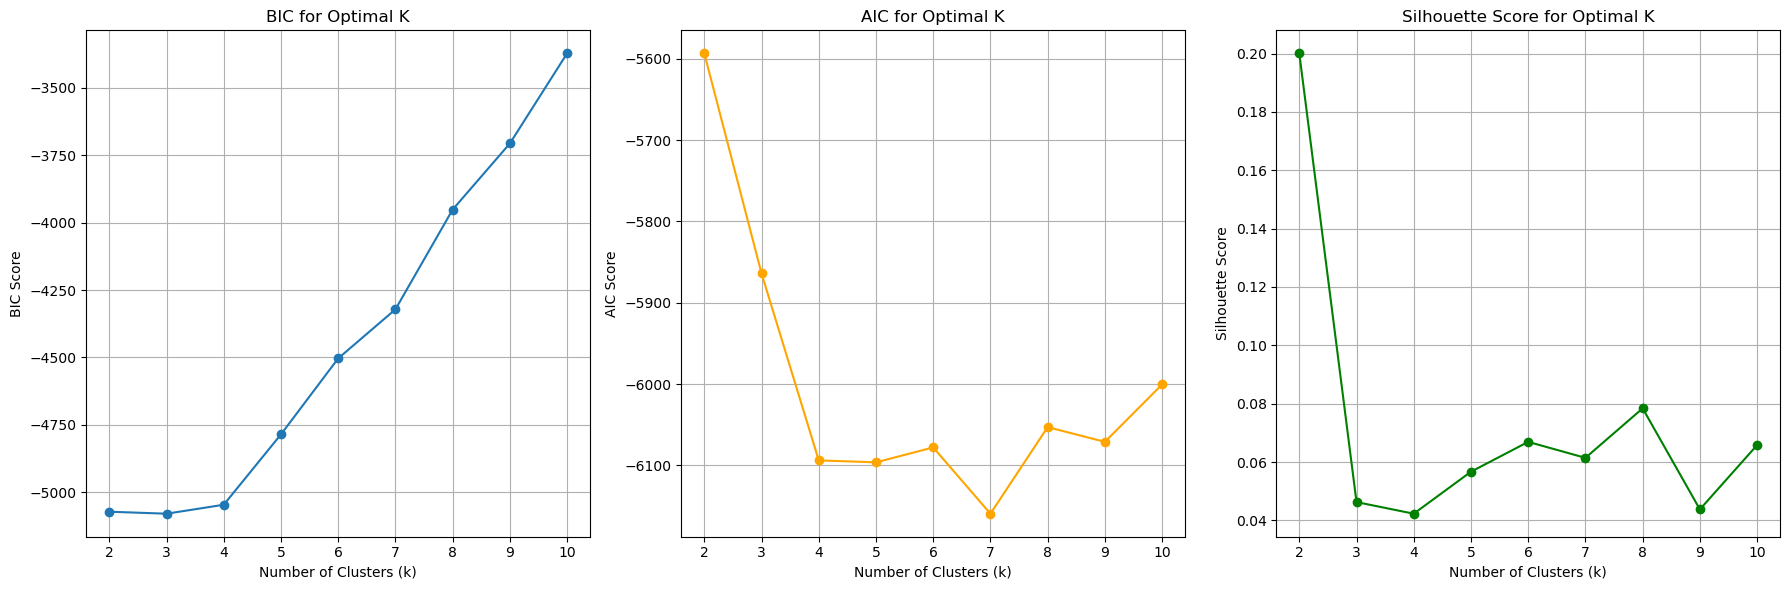

In [9]:
gmm_bic_aic_silhouette_plots(data.iloc[:, idh_train_most_relevant[:10]])

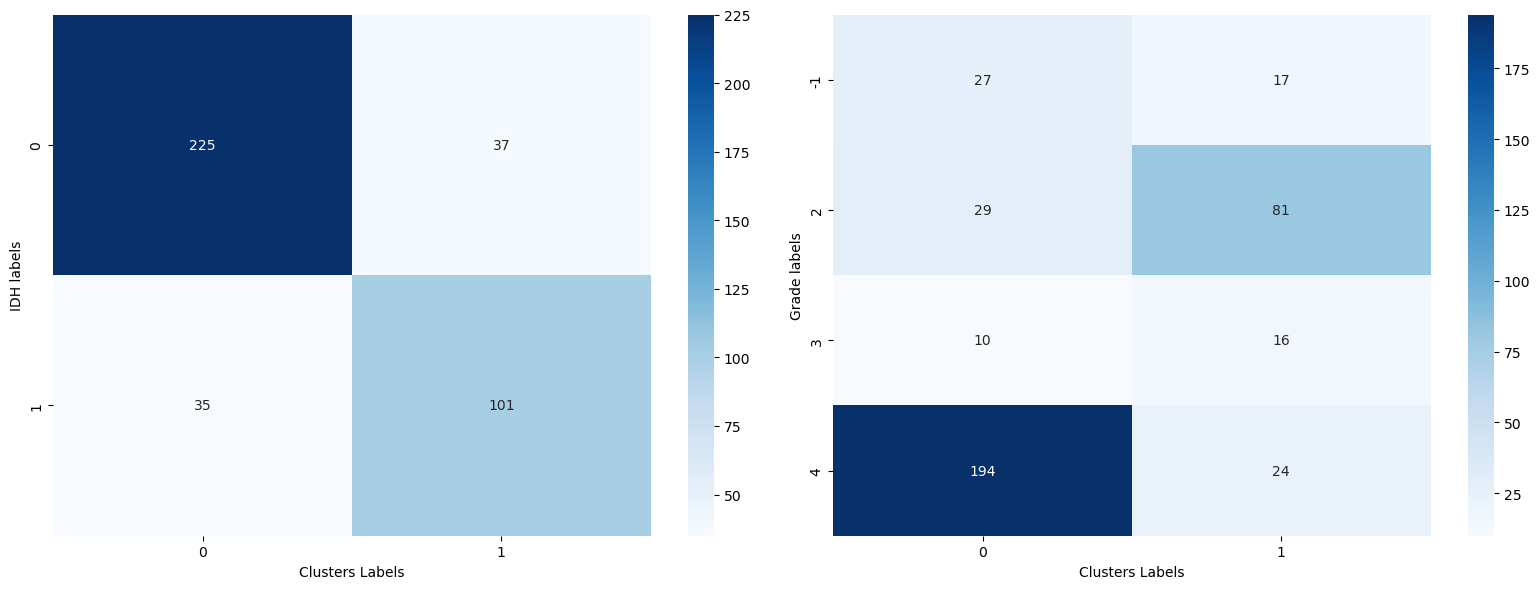

In [10]:
k = 2  # Replace with your known number of clusters

num_features=10

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, idh_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, idh_train_most_relevant[:num_features]])

plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH labels', 'Grade labels'])

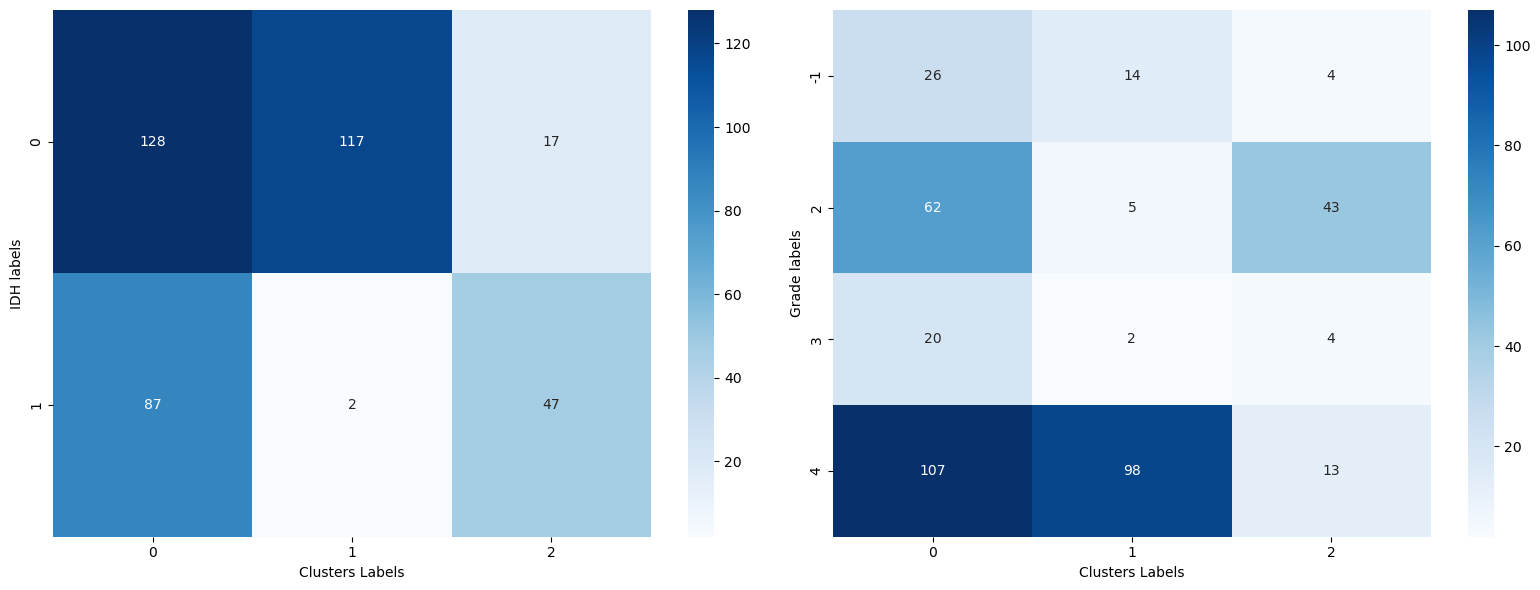

In [11]:
k = 3  # Replace with your known number of clusters

num_features=10

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, idh_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, idh_train_most_relevant[:num_features]])

plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH labels', 'Grade labels'])

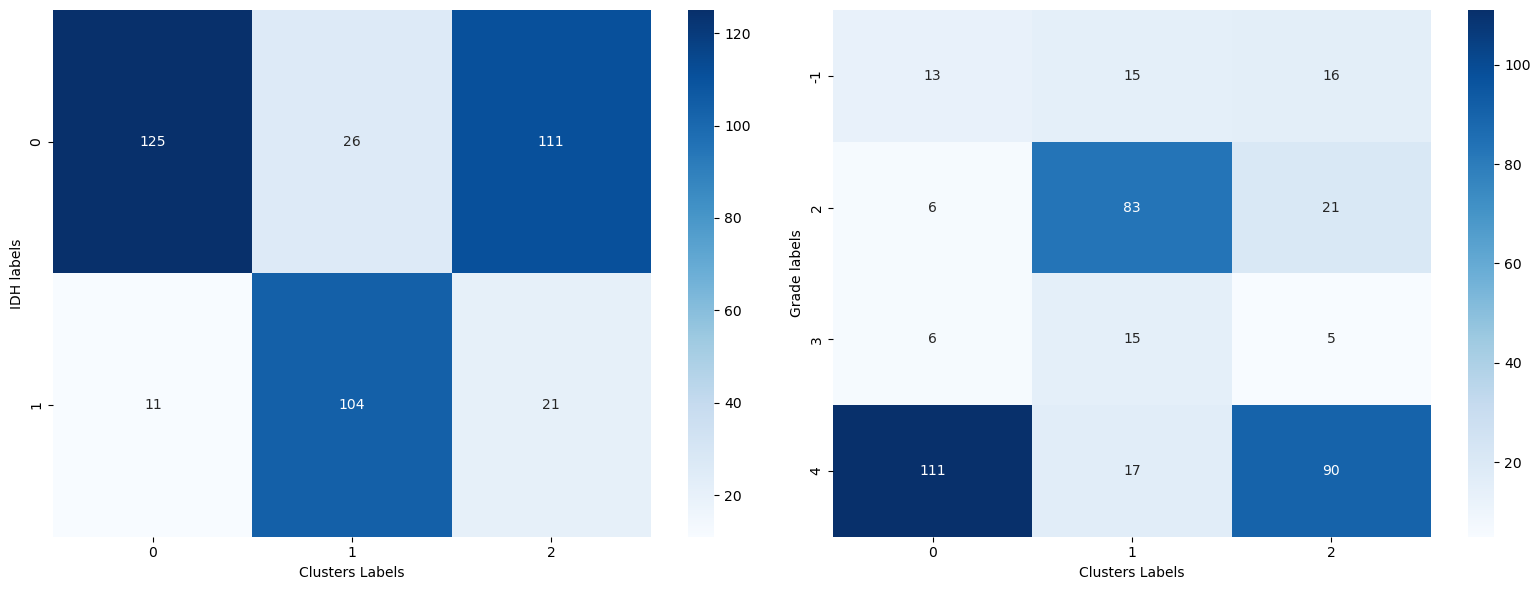

In [12]:
k = 3  # Replace with your known number of clusters

num_features=50

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, idh_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, idh_train_most_relevant[:num_features]])

plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH labels', 'Grade labels'])

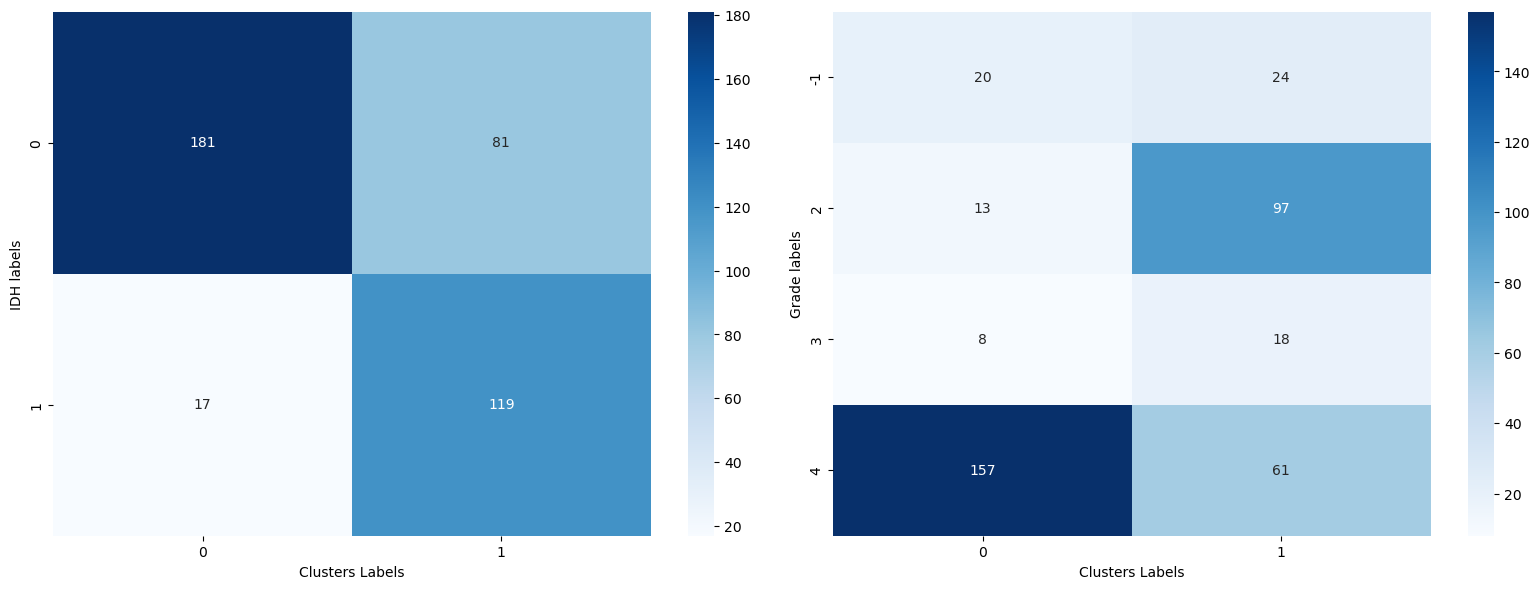

In [13]:
k = 2  # Replace with your known number of clusters

num_features=50

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, idh_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, idh_train_most_relevant[:num_features]])

plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH labels', 'Grade labels'])

In [14]:
total=len(y_train_idh)
(total-7-22-18-11)/total

0.8542713567839196

In [15]:
total=len(y_train_idh)
(total-11-26-21)/total

0.8542713567839196

In [16]:
(total-17-81)/total

0.7537688442211056

None


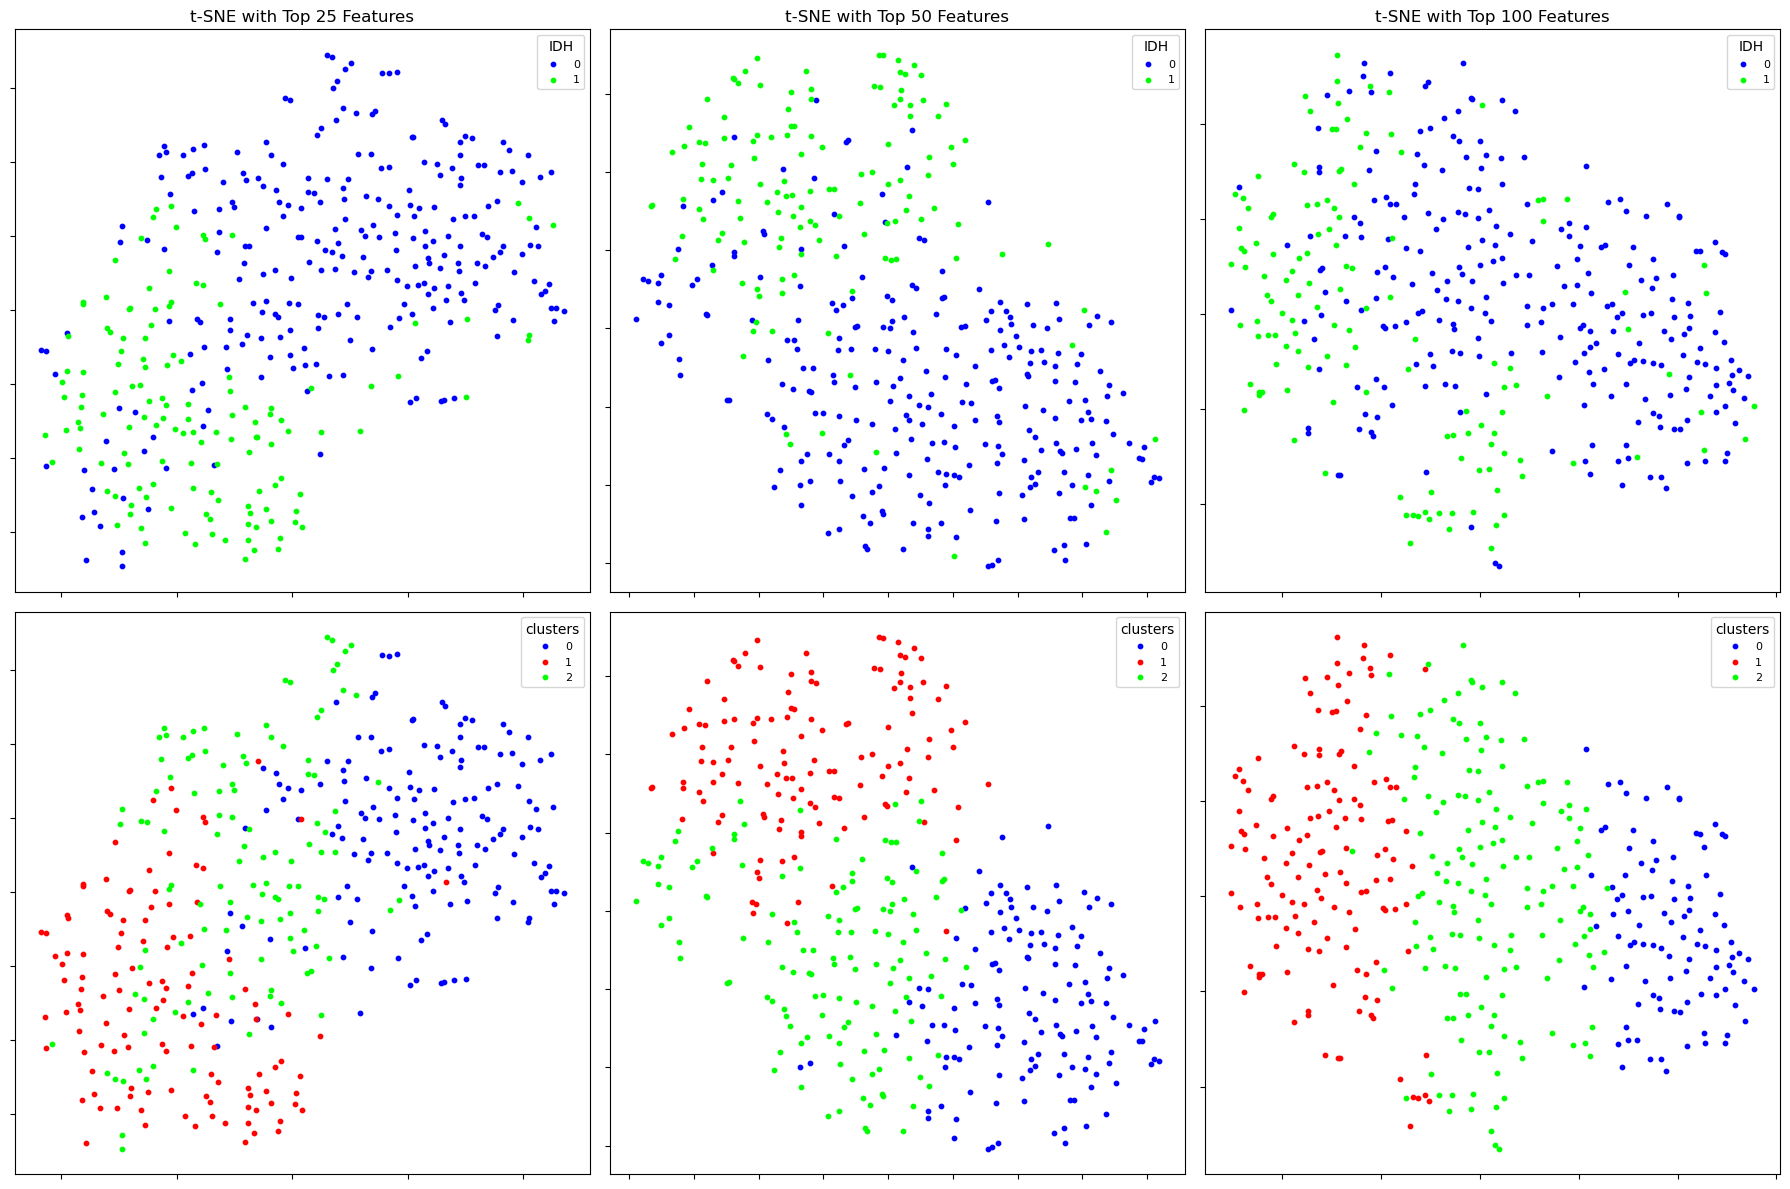

In [17]:
# Define the list of feature counts to test
feature_counts = [25, 50, 100]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, y_train_idh, 3, feature_counts, idh_train_most_relevant, 'GAUSSIANMIX', labels_title='IDH', labels_title_clusters='clusters')

None


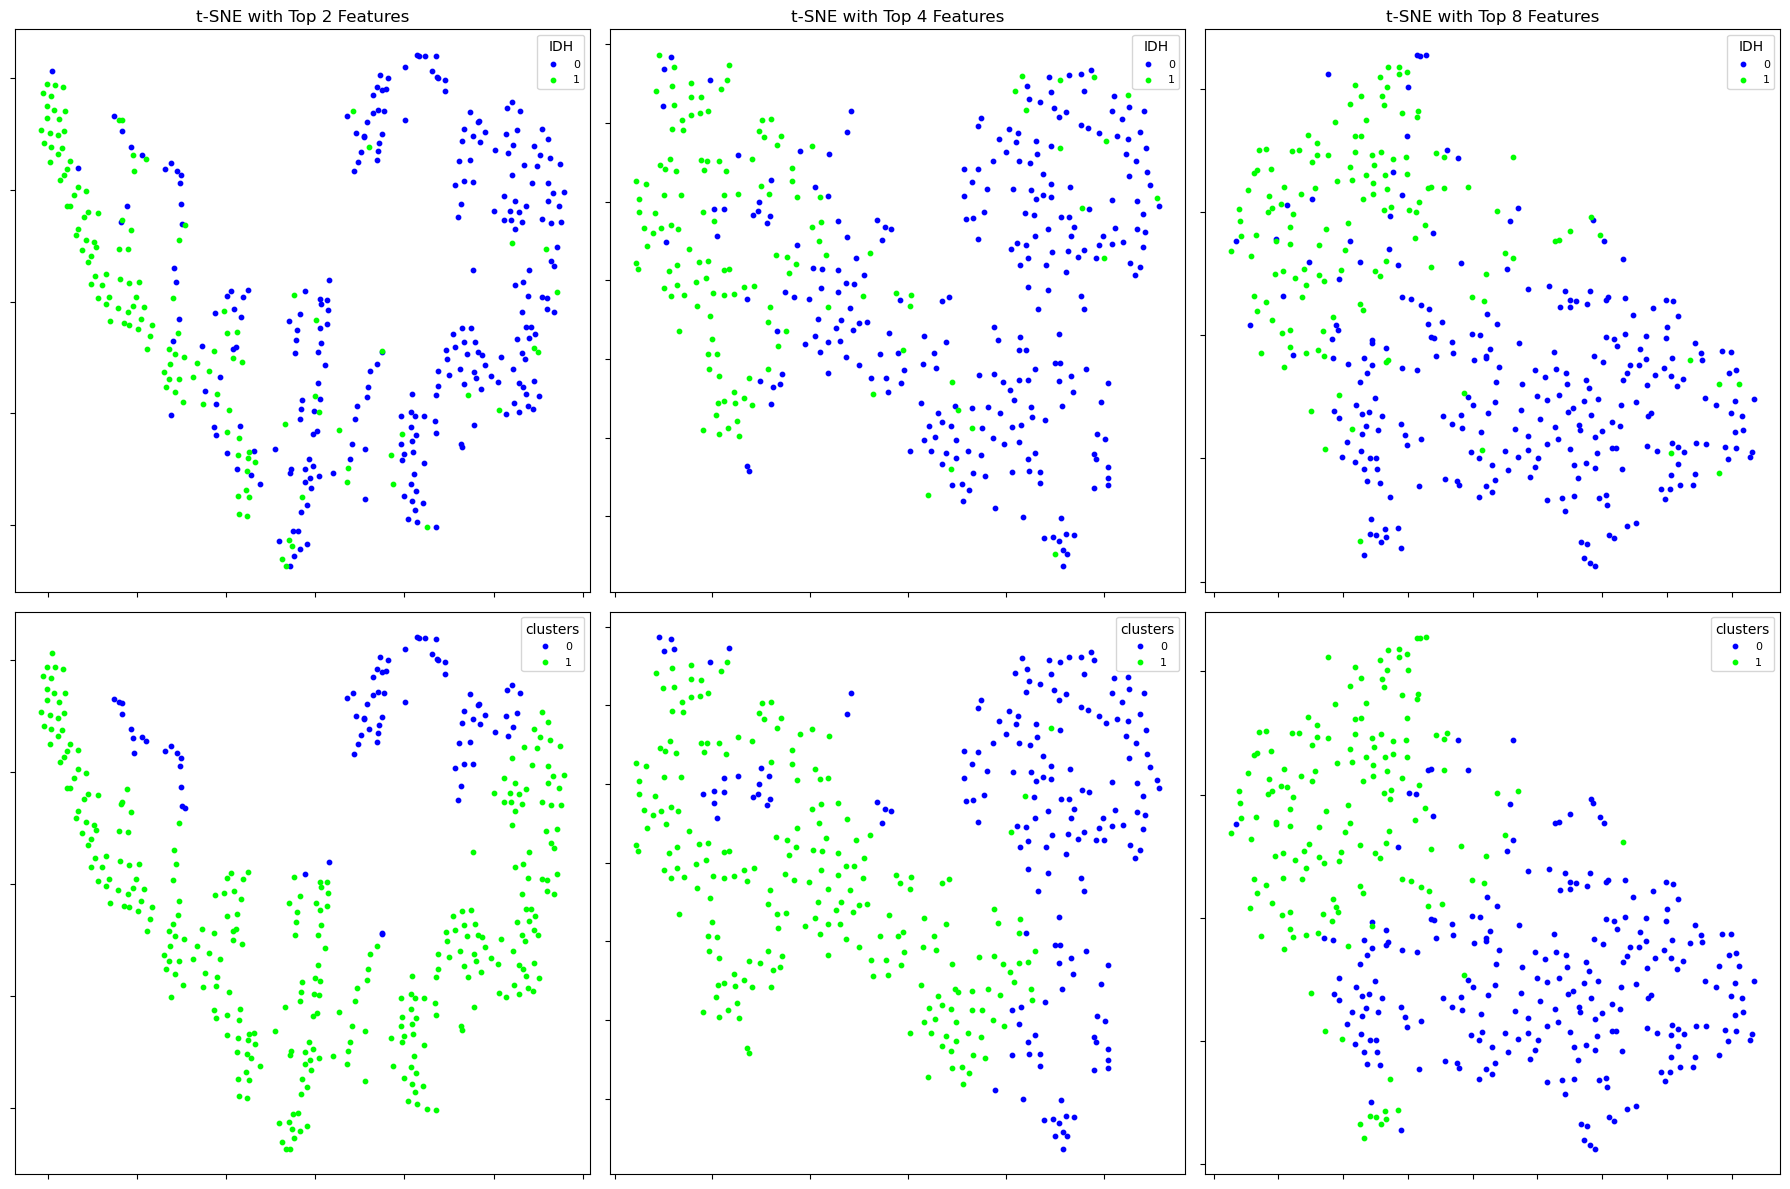

In [18]:
# Define the list of feature counts to test
feature_counts = [2, 4, 8]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, y_train_idh, 2, feature_counts, idh_train_most_relevant, 'GAUSSIANMIX', labels_title='IDH', labels_title_clusters='clusters')

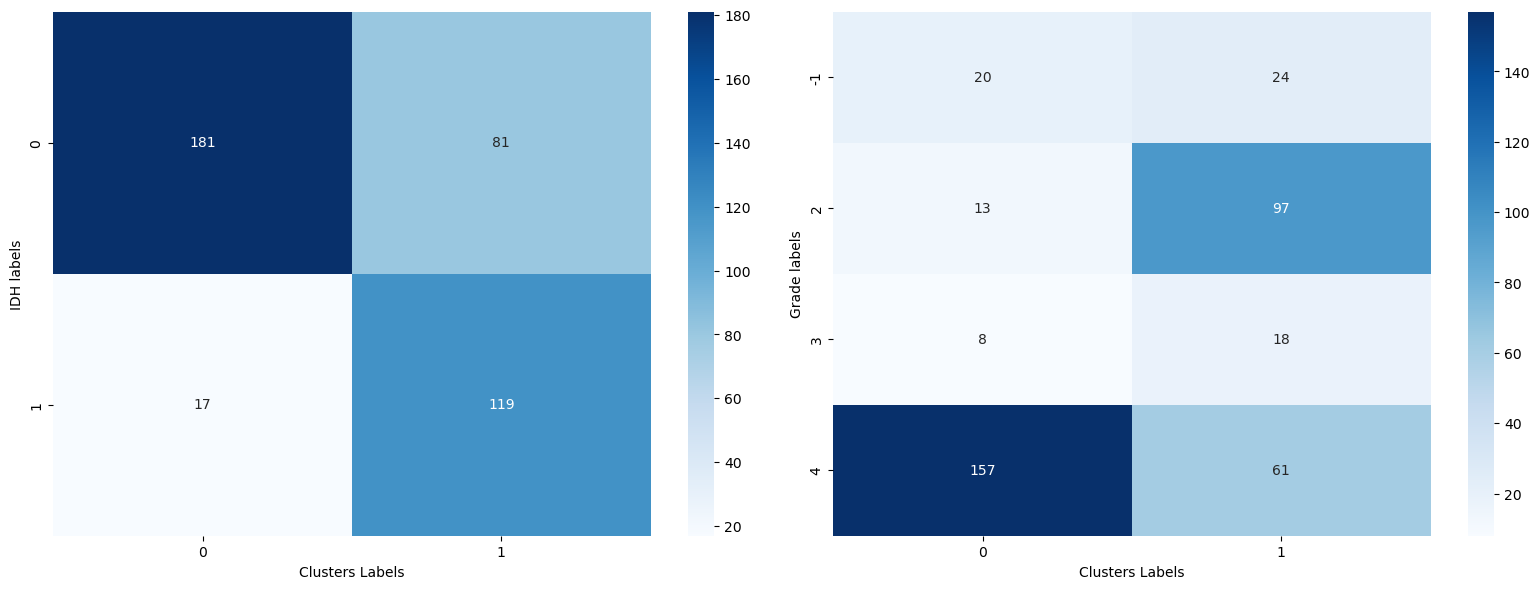

In [19]:
k = 2  # Replace with your known number of clusters

num_features=50

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, idh_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, idh_train_most_relevant[:num_features]])

plot_cm([y_train_idh, grade_train_idh], labels, title_true_label_list=['IDH labels', 'Grade labels'])

### 1p19q

In [38]:
num_features=300
data = selection_anaysis(x_train_merged, y_train_merged, 'ANOVA', features=num_features)

method: ANOVA
Explained Variance (Retained): 1.8565%
Columns from filter 'original': 27
Columns from filter 'exponential': 70
Columns from filter 'gradient': 20
Columns from filter 'lbp-2D': 2
Columns from filter 'lbp-3D-m1': 14
Columns from filter 'lbp-3D-m2': 4
Columns from filter 'lbp-3D-k': 9
Columns from filter 'logarithm': 19
Columns from filter 'square_': 56
Columns from filter 'squareroot': 16
Columns from filter 'wavelet-LLL': 26
Columns from filter 'wavelet-HLL': 9
Columns from filter 'wavelet-LHL': 17
Columns from filter 'wavelet-LLH': 3
Columns from filter 'wavelet-HHL': 4
Columns from filter 'wavelet-HLH': 0
Columns from filter 'wavelet-LHH': 1
Columns from filter 'wavelet-HHH': 2
Wavelet filtered columns: 62
original image columns: 238
Other columns: 1
Columns from image 'original': 86
Columns from image 'mirrored': 0
Columns from contrast 'T1': 69
Columns from contrast 'T2': 229
Columns from contrast 'FLAIR': 1


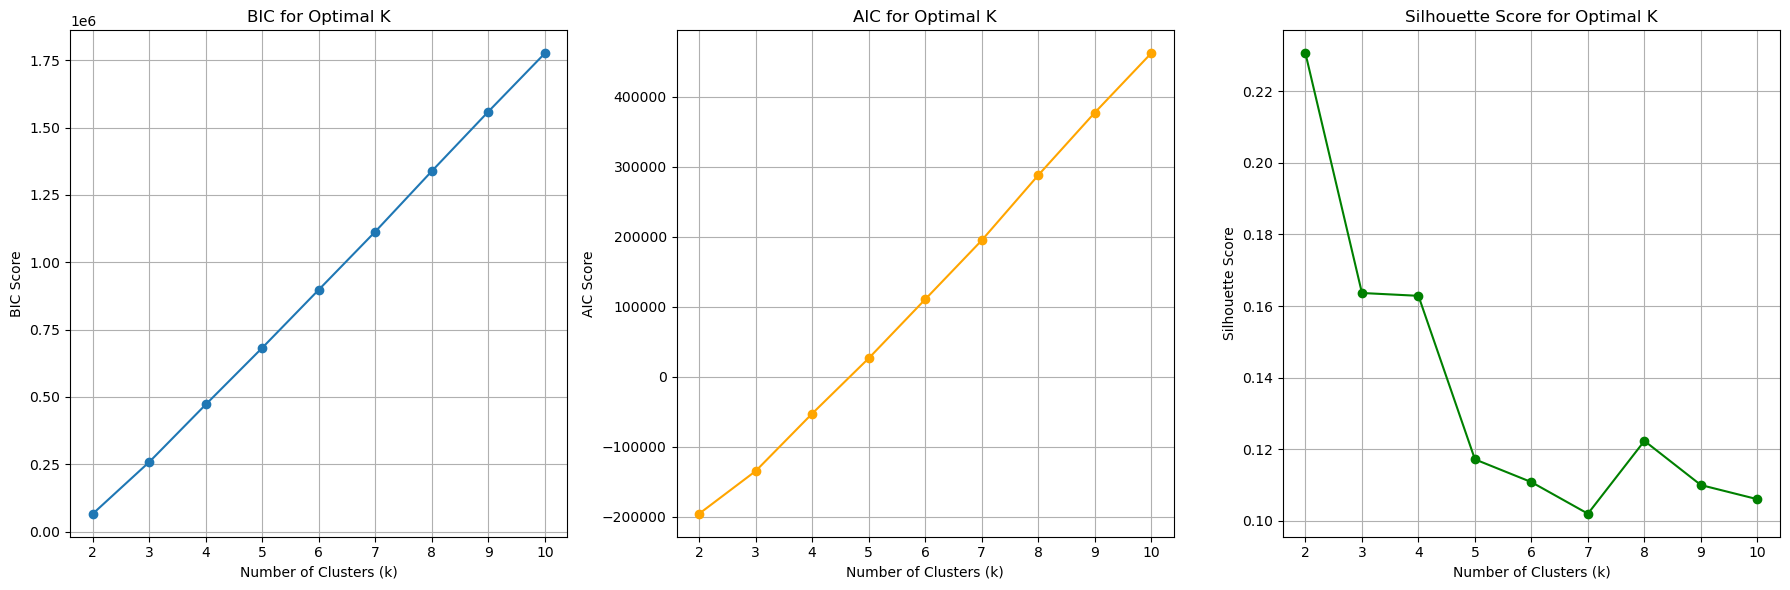

In [39]:
gmm_bic_aic_silhouette_plots(data)

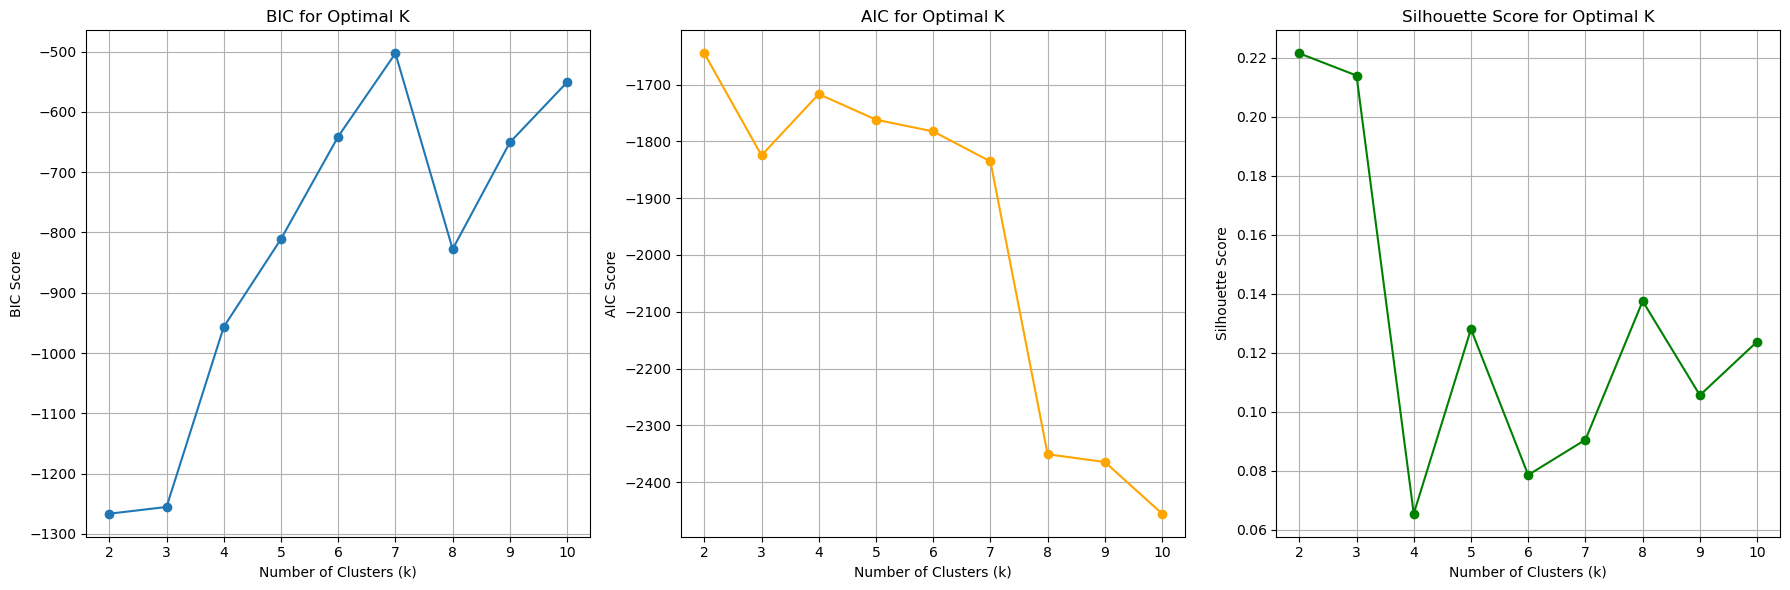

In [40]:
gmm_bic_aic_silhouette_plots(data.iloc[:, merged_train_most_relevant[:10]])

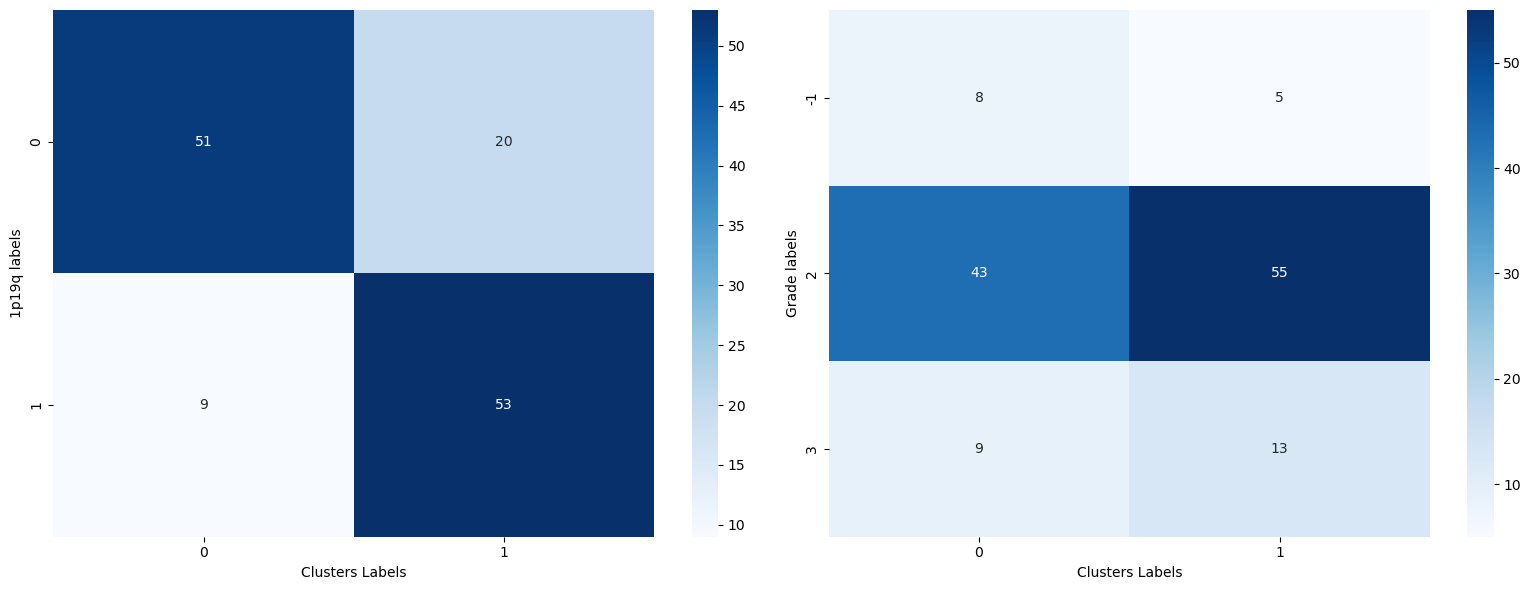

In [63]:
k = 2 # Replace with your known number of clusters

num_features=10

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, merged_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, merged_train_most_relevant[:num_features]])

plot_cm([y_train_merged, grade_train_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

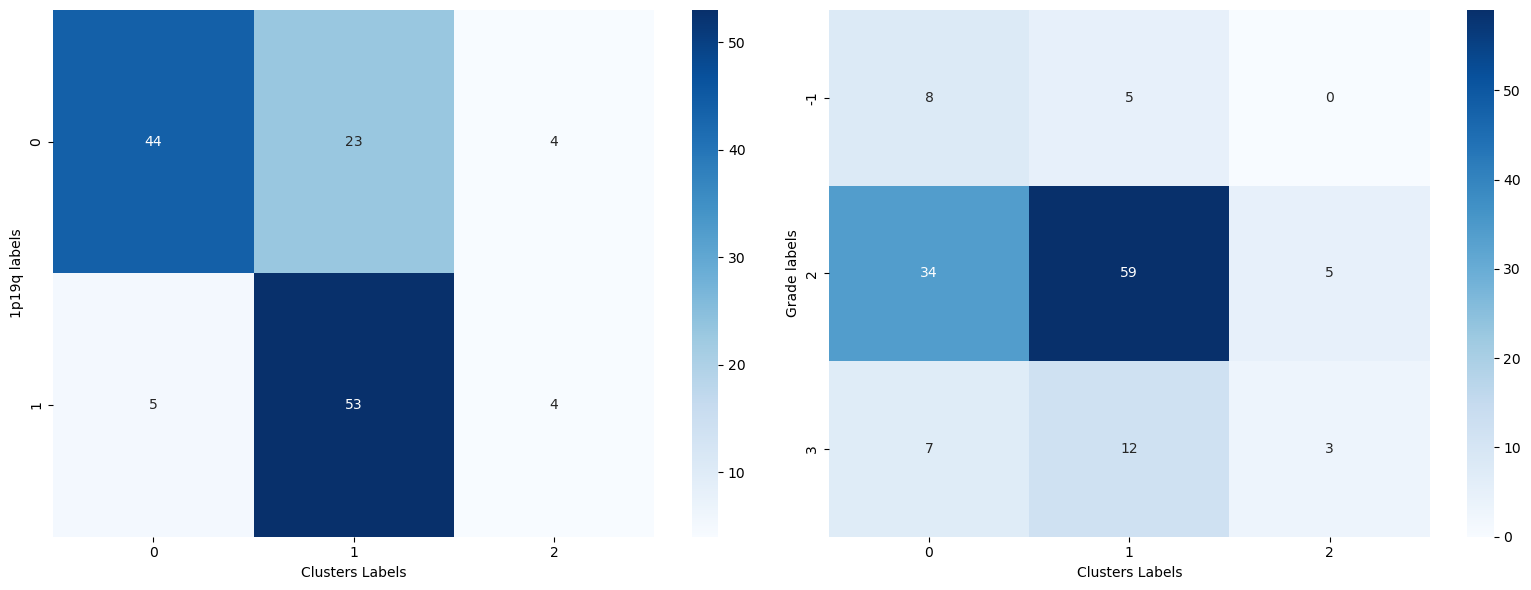

In [42]:
k = 3  # Replace with your known number of clusters

num_features=10

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, merged_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, merged_train_most_relevant[:num_features]])

plot_cm([y_train_merged, grade_train_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

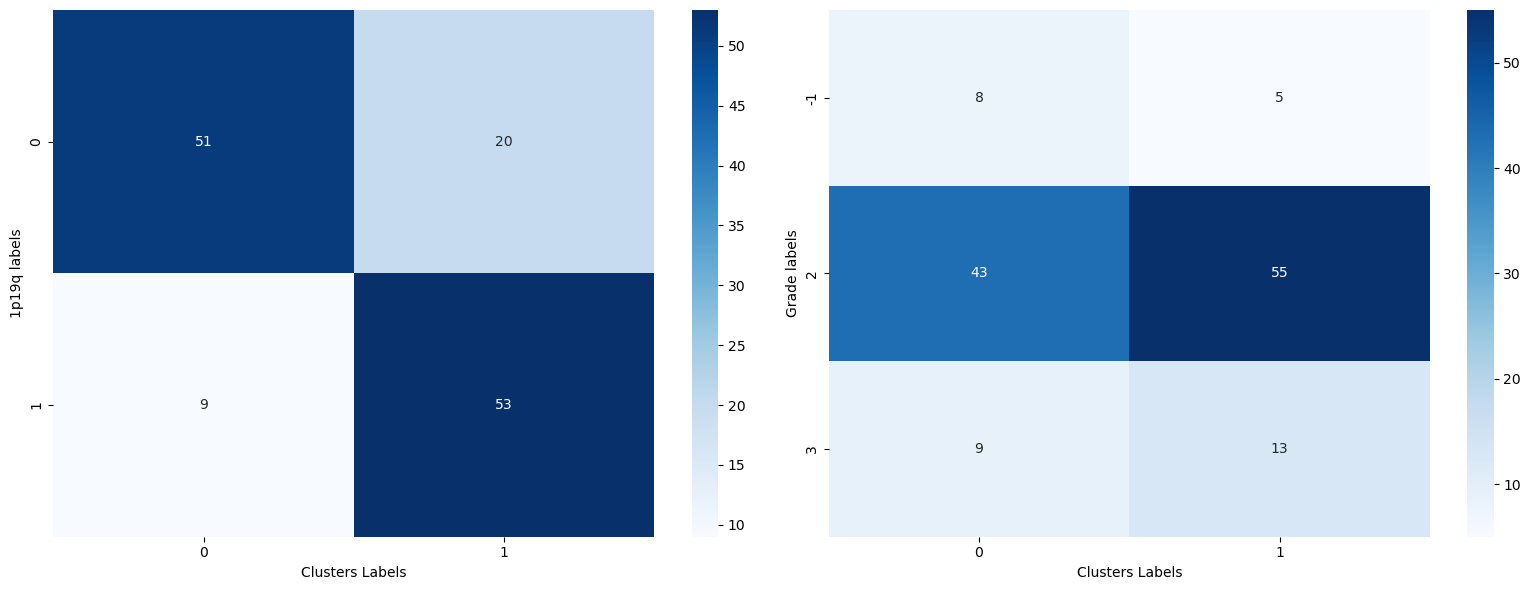

In [43]:
k = 2  # Replace with your known number of clusters

num_features=10

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(data.iloc[:, merged_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(data.iloc[:, merged_train_most_relevant[:num_features]])

plot_cm([y_train_merged, grade_train_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

None


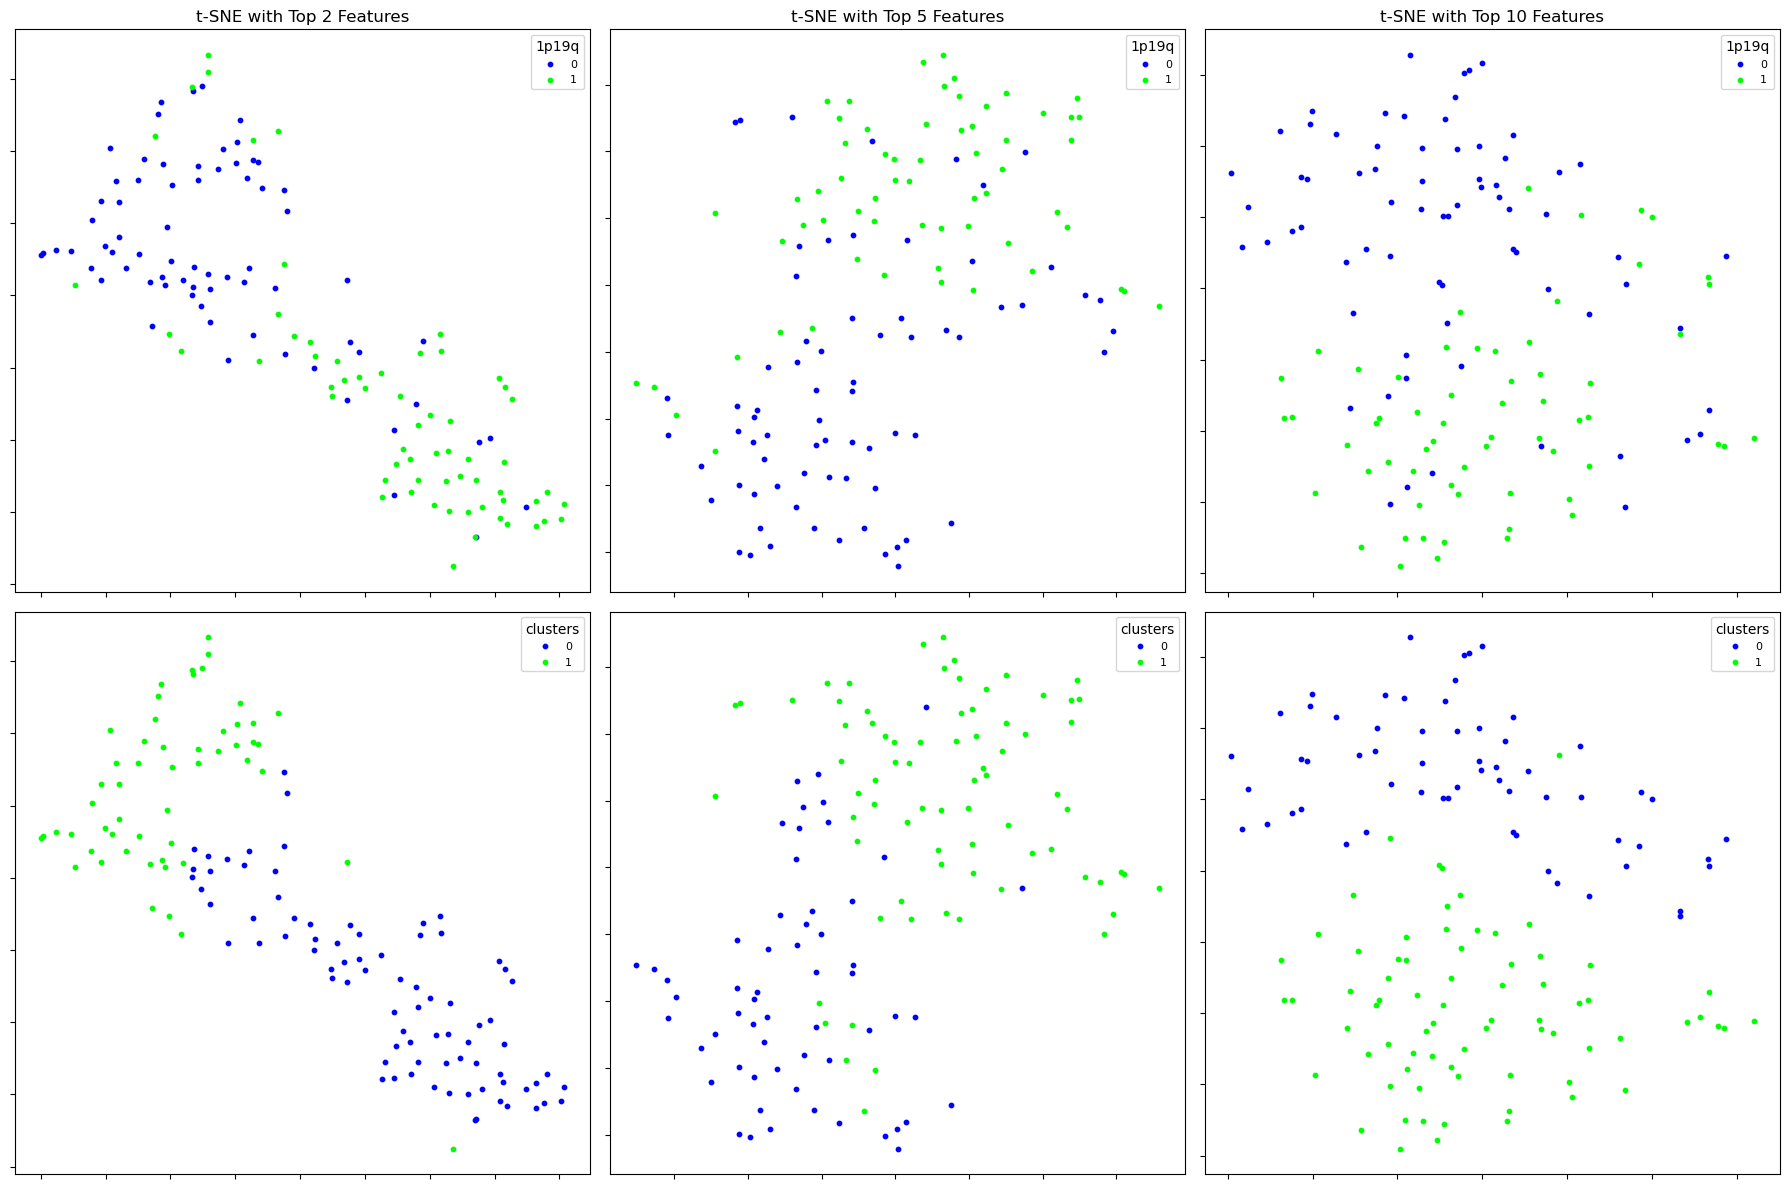

In [44]:
# Define the list of feature counts to test
feature_counts = [2, 5, 10]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, y_train_merged, 2, feature_counts, merged_train_most_relevant, 'GAUSSIANMIX', labels_title='1p19q', labels_title_clusters='clusters')

None


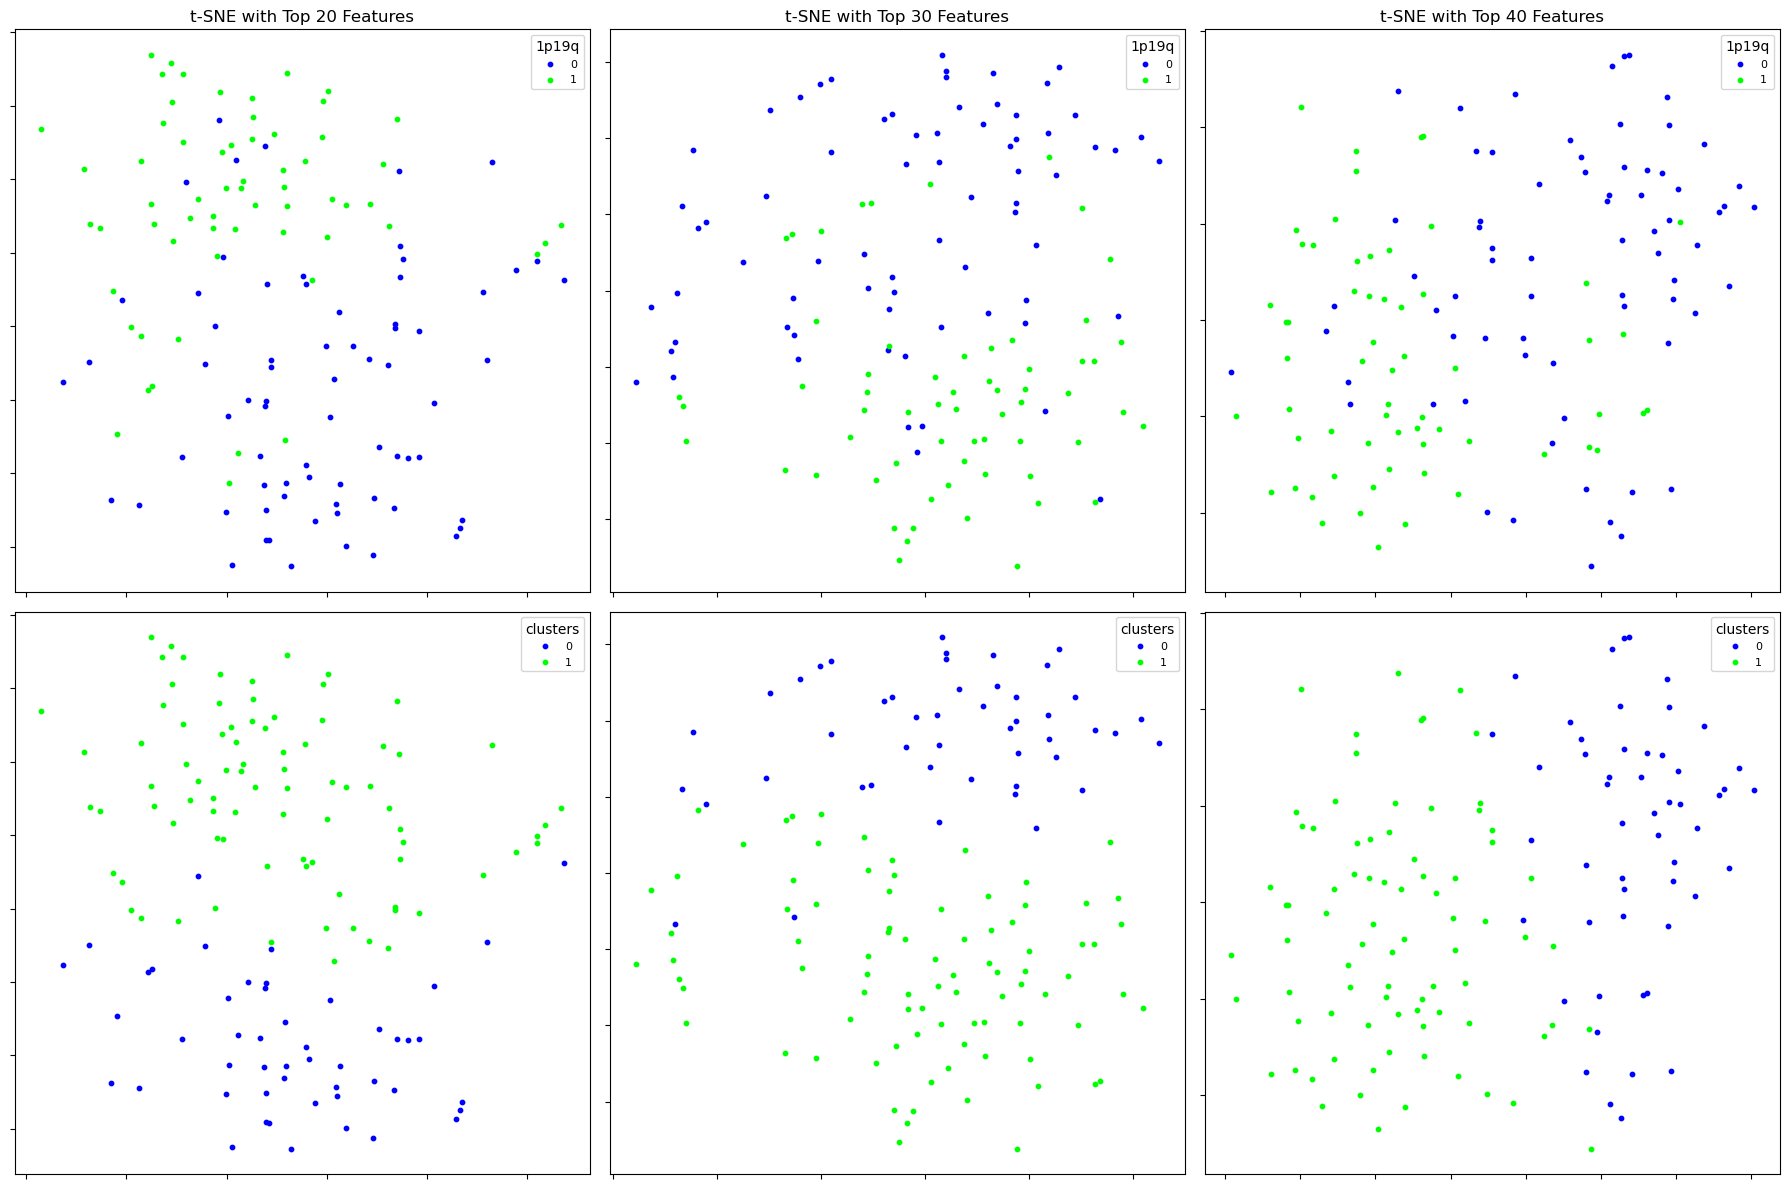

In [45]:
# Define the list of feature counts to test
feature_counts = [20, 30, 40]
title = 't-SNE over IDH x-data varying the number of features selected by ANOVA'

t_sne_plots_clusters_and_labels(data, y_train_merged, 2, feature_counts, merged_train_most_relevant, 'GAUSSIANMIX', labels_title='1p19q', labels_title_clusters='clusters')

## TEST

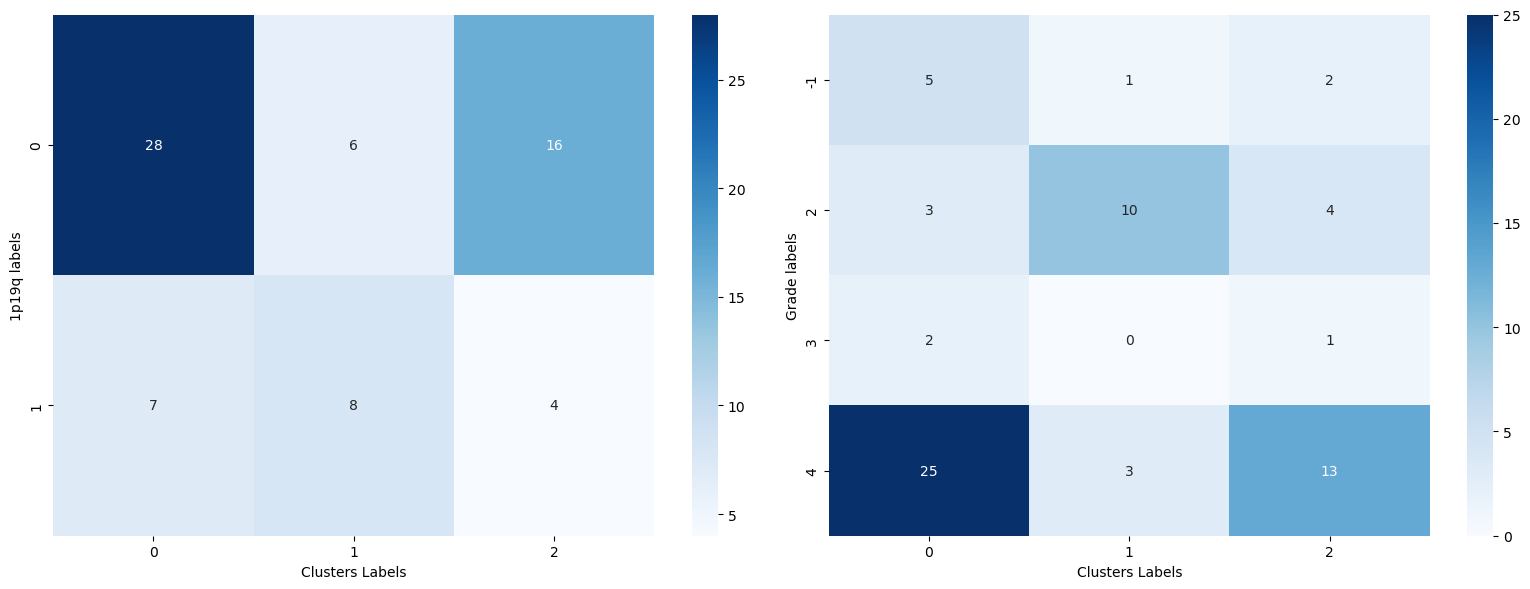

In [54]:
aux_train_idh, aux_test_idh = pre_proc(x_train_idh, y_train_idh, x_test_idh, method='ANOVA', features=500, verbose=False)

k=3
num_features=50

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(aux_train_idh.iloc[:, idh_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(aux_test_idh.iloc[:, idh_train_most_relevant[:num_features]])

plot_cm([y_test_idh, grade_test_idh], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

In [55]:
(28+8+16)/(28+8+16 +7+6+4)

0.7536231884057971

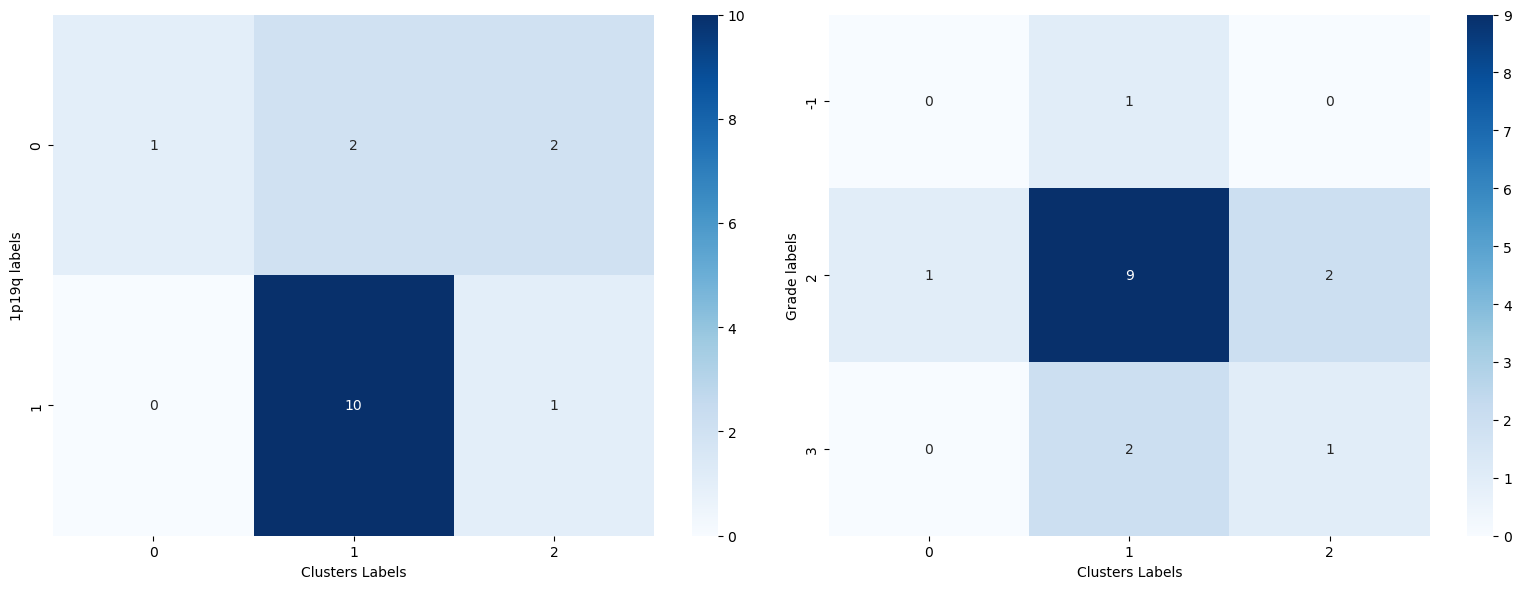

In [60]:
aux_train_merged, aux_test_merged = pre_proc(x_train_merged, y_train_merged, x_test_merged, method='ANOVA', features=300, verbose=False)

num_features=5

# Fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=k, random_state=42)
gmm.fit(aux_train_merged.iloc[:, merged_train_most_relevant[:num_features]])

# Predict cluster labels
labels = gmm.predict(aux_test_merged.iloc[:, merged_train_most_relevant[:num_features]])

plot_cm([y_test_merged, grade_test_merged], labels, title_true_label_list=['1p19q labels', 'Grade labels'])

In [131]:
12/16

0.75

In [35]:
(len(y_test_idh)-7-6-4)/len(y_test_idh)

0.7536231884057971

In [39]:
(len(y_test_idh)-8-6)/len(y_test_idh)

0.7971014492753623

# Auto encoder

In [217]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset


aux_train_idh, aux_test_idh = pre_proc(x_train_idh, y_train_idh, x_test_idh, method='ANOVA', features=1000, verbose=False)

output_dim=500
factor=50

x_to_process=aux_train_idh
# Convert to PyTorch tensor
X_tensor = torch.tensor(x_to_process.values, dtype=torch.float32)



# 2️⃣ Define Autoencoder Model
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=10):
        super(Autoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 8*factor),
            nn.ReLU(),
            nn.Linear(8*factor, 4*factor),
            nn.ReLU(),
            nn.Linear(4*factor, latent_dim)  # Latent Space
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 4*factor),
            nn.ReLU(),
            nn.Linear(4*factor, 8*factor),
            nn.ReLU(),
            nn.Linear(8*factor, input_dim)  # Output should match input dimensions
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# Initialize model
input_dim = x_to_process.shape[1]  # Number of features
latent_dim = min(output_dim, input_dim)  # Choose a compact latent space (5-10 dims)
autoencoder = Autoencoder(input_dim, latent_dim)

# 3️⃣ Train the Autoencoder
criterion = nn.MSELoss()
optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)
epochs = 1000
batch_size = 32

# Dataloader for training
dataset = TensorDataset(X_tensor)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Training loop
for epoch in range(epochs):
    for batch in dataloader:
        inputs = batch[0]
        optimizer.zero_grad()
        outputs = autoencoder(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()
    
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

# 4️⃣ Extract Latent Features
X_latent = autoencoder.encoder(X_tensor).detach().numpy()




Epoch [10/1000], Loss: 0.0111
Epoch [20/1000], Loss: 0.0055
Epoch [30/1000], Loss: 0.0051
Epoch [40/1000], Loss: 0.0046
Epoch [50/1000], Loss: 0.0038
Epoch [60/1000], Loss: 0.0033
Epoch [70/1000], Loss: 0.0033
Epoch [80/1000], Loss: 0.0032
Epoch [90/1000], Loss: 0.0030
Epoch [100/1000], Loss: 0.0027
Epoch [110/1000], Loss: 0.0031
Epoch [120/1000], Loss: 0.0032
Epoch [130/1000], Loss: 0.0023
Epoch [140/1000], Loss: 0.0018
Epoch [150/1000], Loss: 0.0019
Epoch [160/1000], Loss: 0.0018
Epoch [170/1000], Loss: 0.0019
Epoch [180/1000], Loss: 0.0014
Epoch [190/1000], Loss: 0.0015
Epoch [200/1000], Loss: 0.0013
Epoch [210/1000], Loss: 0.0013
Epoch [220/1000], Loss: 0.0014
Epoch [230/1000], Loss: 0.0010
Epoch [240/1000], Loss: 0.0012
Epoch [250/1000], Loss: 0.0011
Epoch [260/1000], Loss: 0.0018
Epoch [270/1000], Loss: 0.0012
Epoch [280/1000], Loss: 0.0010
Epoch [290/1000], Loss: 0.0011
Epoch [300/1000], Loss: 0.0010
Epoch [310/1000], Loss: 0.0010
Epoch [320/1000], Loss: 0.0010
Epoch [330/1000],

In [218]:
# 5️⃣ Apply Clustering
kmeans = KMeans(n_clusters=3, random_state=42).fit(X_latent)
gmm = GaussianMixture(n_components=3, random_state=42).fit(X_latent)

# Get cluster assignments
kmeans_labels = kmeans.labels_
gmm_labels = gmm.predict(X_latent)

# 6️⃣ Visualize Clusters with t-SNE
tsne = TSNE(n_components=2, perplexity=15, random_state=42)
X_tsne = tsne.fit_transform(X_latent)

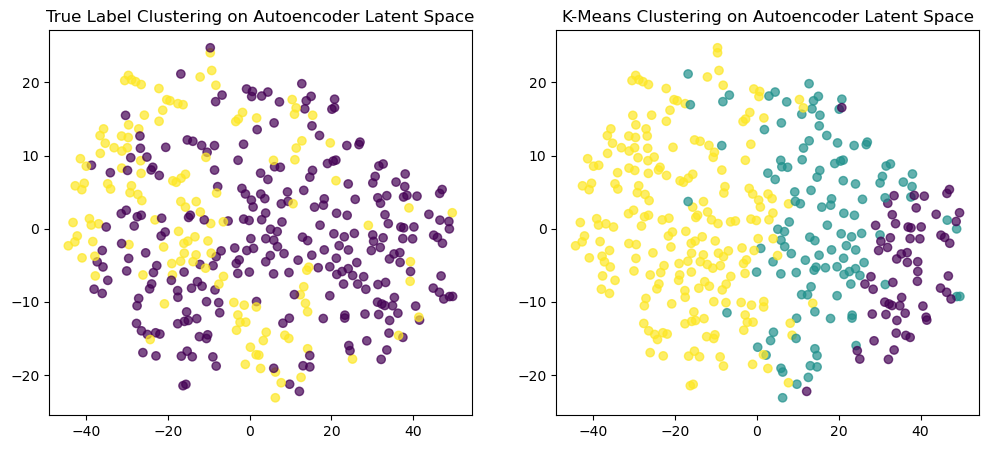

In [219]:


plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_train_idh, cmap="viridis", alpha=0.7)
plt.title("True Label Clustering on Autoencoder Latent Space")


# K-Means Plot
plt.subplot(1, 2, 2)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap="viridis", alpha=0.7)
plt.title("K-Means Clustering on Autoencoder Latent Space")

plt.show()

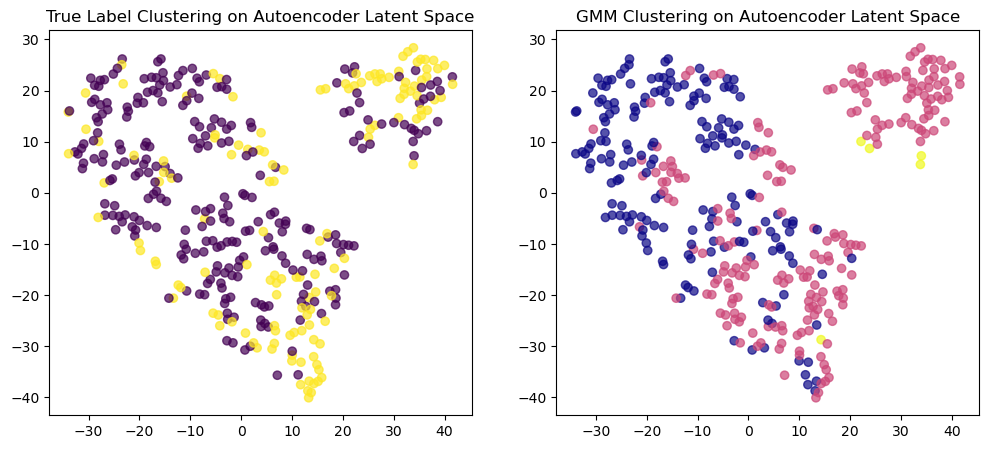

In [211]:
plt.figure(figsize=(12, 5))

# K-Means Plot
plt.subplot(1, 2, 1)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_train_idh, cmap="viridis", alpha=0.7)
plt.title("True Label Clustering on Autoencoder Latent Space")

# GMM Plot
plt.subplot(1, 2, 2)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=gmm_labels, cmap="plasma", alpha=0.7)
plt.title("GMM Clustering on Autoencoder Latent Space")

plt.show()

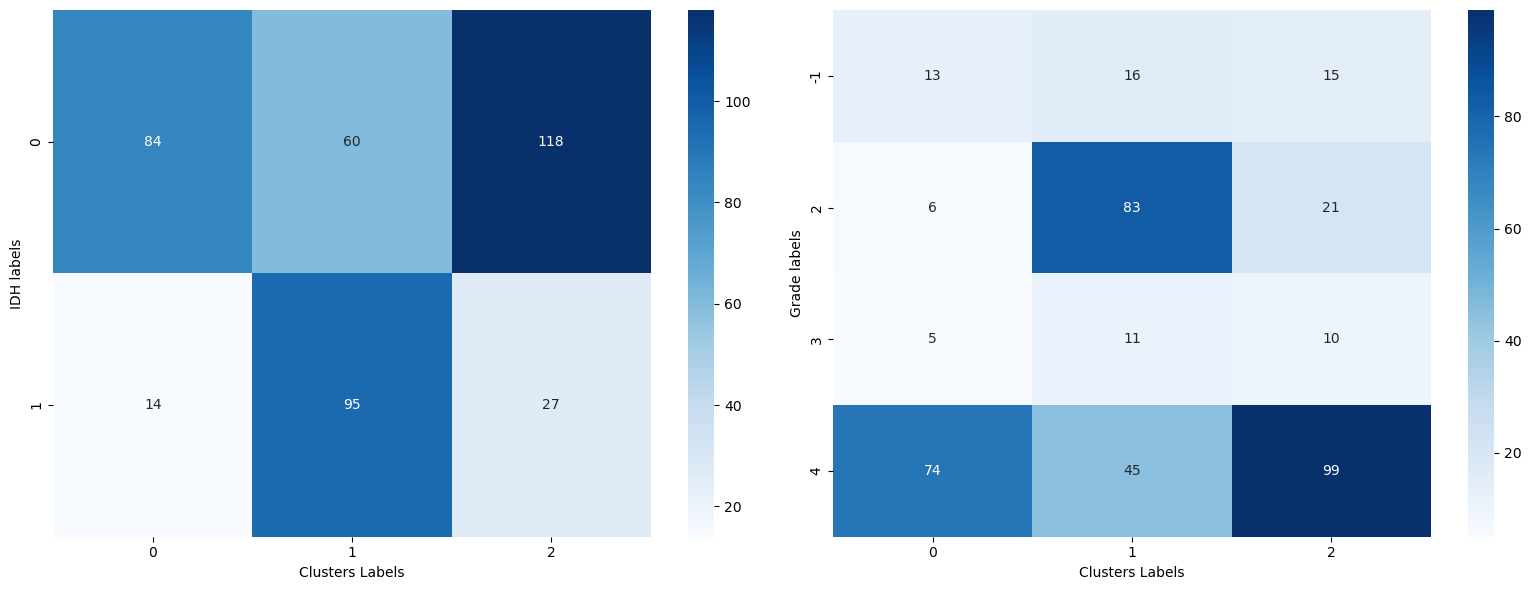

In [182]:
plot_cm([y_train_idh, grade_train_idh], kmeans_labels, title_true_label_list=['IDH labels', 'Grade labels'])